# Topik 3 v5: Fitur intensitas di head, model 3D, dan perbandingan runtime

Tindak lanjut arahan pembimbing minggu ke-4:

1. **Perbandingan runtime**: 2D single slice vs 2D multislice vs 3D (training, inferensi, memori GPU).
2. **Fitur statistik intensitas** (rasio median tumor/otak normal, z-score, P10, P90, fraksi terang/gelap, IQR, skewness,
   kurtosis, bimodality coefficient, entropy) yang **dimasukkan ke head** model, versi 2D (slice lama) dan 3D (semua slice tumor).
3. **Perbandingan hasil** semua pendekatan (target macro-F1 ≥ 0,65) dan **ranking fitur** mana yang membantu / tidak.

Analisis yang tetap dipertahankan: **5-fold CV per pasien** (untuk memilih model final) dan **top-2 confidence + kalibrasi**.

**Pengaturan Kaggle:** Accelerator **GPU T4**, Internet **On**, input = output notebook ekstraksi multislice (sama dengan v4).
Jalankan dengan **Save Version → Save & Run All**. Estimasi ±2–3 jam.

In [1]:
import os, glob, json, math, time, random, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage as ndi, stats
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
try:
    import timm
except ImportError:
    os.system("pip install -q timm")
    import timm
import torchvision
print("torch", torch.__version__, "| timm", timm.__version__, "| torchvision", torchvision.__version__, "| CUDA", torch.cuda.is_available())

torch 2.11.0+cu128 | timm 1.0.29 | torchvision 0.26.0+cu128 | CUDA True


## 1. Konfigurasi & lokasi data

In [2]:
def find_ms_root():
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count(os.sep) > 9:
            dirs[:] = []; continue
        if "records.csv" in files and "slices.csv" in files and "volumes" in dirs:
            return root
    print("Isi /kaggle/input (untuk cek):")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count(os.sep) <= 6:
            print("  ", root, "|", len(files), "file")
    raise AssertionError("Output ekstraksi tidak ditemukan. Tambahkan output notebook ekstraksi multislice ke Input.")

MS_ROOT = os.environ.get("MS_ROOT") or find_ms_root()
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working/v5_outputs")
RUNS_DIR = os.path.join(OUT_DIR, "runs"); CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
os.makedirs(RUNS_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("MS_ROOT:", MS_ROOT, "| OUT_DIR:", OUT_DIR, "| device:", DEVICE)

IMG_SIZE = 224
SEEDS = [42, 1337, 2024]
MAX_SLICES = 10            # batas multislice 2D
VOL_DEPTH = 16             # jumlah slice untuk model 3D (seluruh tumor di-resample ke 16 slice)
VOL_SIZE = 112
TARGET_F1 = 0.65

CFG = dict(   # sama dengan model final v3/v4
    backbone="vit_small_patch16_224.augreg_in21k_ft_in1k",
    input_mode="roi", roi_margin=2.0, roi_min=72, augment=True, elastic=True,
    epochs=40, patience=10, warmup_epochs=2, batch_size=32,
    lr_backbone=3e-5, lr_head=1e-3, wd=0.05, dropout=0.3, label_smoothing=0.05,
    w_modality=0.3, w_signal=1.0, tta=True, feat_dim=64, feat_dropout=0.2,
)
CFG3D = dict(CFG, elastic=False, epochs=30, patience=8, batch_size=8, lr_backbone=1e-4)

MS_ROOT: /kaggle/input/notebooks/mashitasafa/topik-3/brain_signal_multislice | OUT_DIR: /kaggle/working/v5_outputs | device: cuda


## 2. Load data ke RAM

In [3]:
records = pd.read_csv(os.path.join(MS_ROOT, "records.csv"))
slices = pd.read_csv(os.path.join(MS_ROOT, "slices.csv"))
MOD_CLASSES = ["t1n", "t2f", "t2w"]
SIG_CLASSES = ["hyperintense", "hypointense", "isointense", "mixed"]
records["mod_y"] = records.modality.map({c: i for i, c in enumerate(MOD_CLASSES)})
records["sig_y"] = records.signal_label.map({c: i for i, c in enumerate(SIG_CLASSES)})
records = records.reset_index(drop=True)

t0 = time.time()
VOL = {}
for pf in records.prefix.unique():
    z = np.load(os.path.join(MS_ROOT, "volumes", pf + ".npz"))
    VOL[pf] = {k: z[k] for k in ["slice_idx", "seg", "t1n", "t2w", "t2f"]}
print(f"{len(VOL)} pasien dimuat dalam {time.time() - t0:.0f}s")
print(records.split.value_counts().to_dict())

split_idx = {s: records.index[records.split == s].values for s in ["train", "val", "test"]}
y_sig, y_mod = records.sig_y.values, records.mod_y.values

def k_old(prefix, old_idx):
    return int(np.where(VOL[prefix]["slice_idx"].astype(int) == old_idx)[0][0])

def slice_set(prefix, old_idx, mode):
    si = VOL[prefix]["slice_idx"].astype(int)
    if mode == "old":
        return [k_old(prefix, old_idx)]
    if mode == "win4":
        return [int(k) for k in np.where(np.abs(si - old_idx) <= 4)[0]]
    raise ValueError(mode)

def vol_ks(prefix):
    """Indeks slice untuk model 3D: semua slice tumor di-resample merata ke VOL_DEPTH slice."""
    n = len(VOL[prefix]["slice_idx"])
    return np.round(np.linspace(0, n - 1, VOL_DEPTH)).astype(int)

SETS = {(r.prefix, m): slice_set(r.prefix, int(r.slice_idx), m)
        for r in records.drop_duplicates("prefix").itertuples() for m in ["old", "win4"]}
assert max(len(v) for v in SETS.values()) <= MAX_SLICES
n_tumor_slices = pd.Series({p: len(v["slice_idx"]) for p, v in VOL.items()})
print("Slice tumor per pasien (dipakai fitur 3D): median", int(n_tumor_slices.median()),
      "| min", n_tumor_slices.min(), "| max", n_tumor_slices.max())

377 pasien dimuat dalam 101s
{'train': 756, 'test': 171, 'val': 163}
Slice tumor per pasien (dipakai fitur 3D): median 58 | min 3 | max 123


## 3. Fitur statistik intensitas

Semua intensitas dinyatakan **relatif terhadap otak normal di slice yang sama** (otak di luar tumor yang didilatasi 5 piksel):
`r = I / median(otak normal)` dan `z = (I − median) / std(otak normal)`. Ini penting karena tiap slice dinormalisasi min-max sendiri,
dan karena label hyper/hypo/iso memang didefinisikan relatif terhadap jaringan sekitar.

11 statistik dari tabel pembimbing dihitung untuk 6 area: **inti tumor** (NCR+ET; kalau tidak ada, dipakai tumor utuh),
**tumor utuh**, **edema**, **NCR**, **ET**, dan **jaringan sekitar** (cincin 2–10 piksel di luar tumor), ditambah 4 fitur komposisi
(proporsi NCR/edema/ET dan log luas tumor). Total 70 fitur.

- **Fitur 2D**: dari slice lama saja (sama dengan dataset 2D).
- **Fitur 3D**: piksel dari **semua slice tumor** pasien digabung (setelah dinormalisasi per slice).

In [4]:
STATS = ["rasio_median", "zscore_median", "rasio_p10", "rasio_p90", "frac_terang", "frac_gelap",
         "iqr_rel", "skewness", "kurtosis", "bimodality", "entropy"]
STAT_LABEL = {
    "rasio_median": "Rasio median tumor ÷ median otak normal", "zscore_median": "Z-score median tumor vs otak normal",
    "rasio_p10": "Rasio P10 ÷ otak normal", "rasio_p90": "Rasio P90 ÷ otak normal",
    "frac_terang": "Fraksi piksel > 1,2× normal", "frac_gelap": "Fraksi piksel < 0,8× normal",
    "iqr_rel": "IQR ÷ median otak normal", "skewness": "Skewness", "kurtosis": "Kurtosis",
    "bimodality": "Bimodality coefficient", "entropy": "Entropy", "komposisi": "Komposisi (proporsi NCR/edema/ET, luas)"}
REGIONS = ["inti", "tumor_utuh", "edema", "ncr", "et", "sekitar"]
KOMPOSISI = ["komposisi__frac_ncr", "komposisi__frac_edema", "komposisi__frac_et", "komposisi__log_luas"]
FEAT_COLS = [f"{r}__{s}" for r in REGIONS for s in STATS] + KOMPOSISI
MIN_PX, MIN_NORMAL = 20, 200

def stat_block(r, z):
    out = dict.fromkeys(STATS, np.nan)
    if r.size < MIN_PX:
        return out
    p10, p25, p50, p75, p90 = np.percentile(r, [10, 25, 50, 75, 90])
    g, k, n = float(stats.skew(r)), float(stats.kurtosis(r)), r.size
    h, _ = np.histogram(np.clip(r, 0, 3), bins=60, range=(0, 3)); p = h[h > 0] / h.sum()
    out.update(rasio_median=p50, zscore_median=float(np.median(z)), rasio_p10=p10, rasio_p90=p90,
               frac_terang=float((r > 1.2).mean()), frac_gelap=float((r < 0.8).mean()), iqr_rel=p75 - p25,
               skewness=g, kurtosis=k, bimodality=(g ** 2 + 1) / (k + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3))),
               entropy=float(-(p * np.log2(p)).sum()))
    return out

def dilate_local(mask, it):
    """binary_dilation hanya di sekitar bbox (jauh lebih cepat untuk slice 240x240)."""
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return mask.copy()
    y0, y1 = max(ys.min() - it - 1, 0), min(ys.max() + it + 2, mask.shape[0])
    x0, x1 = max(xs.min() - it - 1, 0), min(xs.max() + it + 2, mask.shape[1])
    out = np.zeros_like(mask)
    out[y0:y1, x0:x1] = ndi.binary_dilation(mask[y0:y1, x0:x1], iterations=it)
    return out

def intensity_features(prefix, modality, ks):
    v = VOL[prefix]
    acc = {r: ([], []) for r in REGIONS}; counts = dict(ncr=0, edema=0, et=0, tumor=0)
    for k in ks:
        img, seg = v[modality][k].astype(np.float32), v["seg"][k]
        tumor = seg > 0
        normal = (img > 0) & ~dilate_local(tumor, 5)
        if normal.sum() < MIN_NORMAL or tumor.sum() == 0:
            continue
        nv = img[normal]; med = float(np.median(nv)) + 1e-3; sd = float(nv.std()) + 1e-3
        r, z = img / med, (img - med) / sd
        masks = dict(tumor_utuh=tumor, edema=seg == 2, ncr=seg == 1, et=seg == 3, inti=(seg == 1) | (seg == 3),
                     sekitar=dilate_local(tumor, 10) & ~dilate_local(tumor, 2) & (img > 0))
        for name, m in masks.items():
            acc[name][0].append(r[m]); acc[name][1].append(z[m])
        counts["ncr"] += int((seg == 1).sum()); counts["edema"] += int((seg == 2).sum())
        counts["et"] += int((seg == 3).sum()); counts["tumor"] += int(tumor.sum())
    cat = lambda L: np.concatenate(L) if L else np.zeros(0, np.float32)
    pooled = {name: (cat(a[0]), cat(a[1])) for name, a in acc.items()}
    if pooled["inti"][0].size < MIN_PX:                  # sebagian MEN tidak punya inti tumor: pakai tumor utuh
        pooled["inti"] = pooled["tumor_utuh"]
    f = {}
    for name in REGIONS:
        for s, val in stat_block(*pooled[name]).items():
            f[f"{name}__{s}"] = val
    T = max(counts["tumor"], 1)
    f.update({"komposisi__frac_ncr": counts["ncr"] / T, "komposisi__frac_edema": counts["edema"] / T,
              "komposisi__frac_et": counts["et"] / T, "komposisi__log_luas": float(np.log1p(counts["tumor"]))})
    return f, pooled["inti"][0]

FEAT, FEAT_TIME = {}, {}
for dim in ["2d", "3d"]:
    t0 = time.time(); rows = []
    for r in records.itertuples():
        ks = SETS[(r.prefix, "old")] if dim == "2d" else list(range(len(VOL[r.prefix]["slice_idx"])))
        rows.append(intensity_features(r.prefix, r.modality, ks)[0])
    FEAT[dim] = pd.DataFrame(rows, index=records.index)[FEAT_COLS]
    FEAT_TIME[dim] = (time.time() - t0) / len(records) * 1000
    print(f"Fitur {dim.upper()}: {FEAT[dim].shape[1]} fitur, {FEAT_TIME[dim]:.1f} ms/record, "
          f"NaN rata-rata {FEAT[dim].isna().mean().mean():.1%}")
pd.concat([records[["prefix", "modality", "category", "split", "signal_label"]],
           FEAT["2d"].add_prefix("2d:"), FEAT["3d"].add_prefix("3d:")], axis=1).to_csv(os.path.join(OUT_DIR, "v5_features.csv"), index=False)

Fitur 2D: 70 fitur, 10.8 ms/record, NaN rata-rata 11.1%
Fitur 3D: 70 fitur, 124.6 ms/record, NaN rata-rata 7.6%


signal_label                             hyperintense  hypointense  isointense  mixed
Rasio median tumor ÷ median otak normal          1.37         0.95        0.97   1.37
Z-score median tumor vs otak normal              1.17        -0.21       -0.10   0.96
Rasio P10 ÷ otak normal                          1.09         0.83        0.80   1.07
Rasio P90 ÷ otak normal                          1.62         1.08        1.12   1.77
Fraksi piksel > 1,2× normal                      0.79         0.02        0.03   0.78
Fraksi piksel < 0,8× normal                      0.01         0.06        0.10   0.01
IQR ÷ median otak normal                         0.27         0.15        0.15   0.31
Skewness                                        -0.17        -0.03       -0.18   0.25
Kurtosis                                         0.78         0.62        1.67   0.72
Bimodality coefficient                           0.41         0.37        0.40   0.38
Entropy                                          4.03 

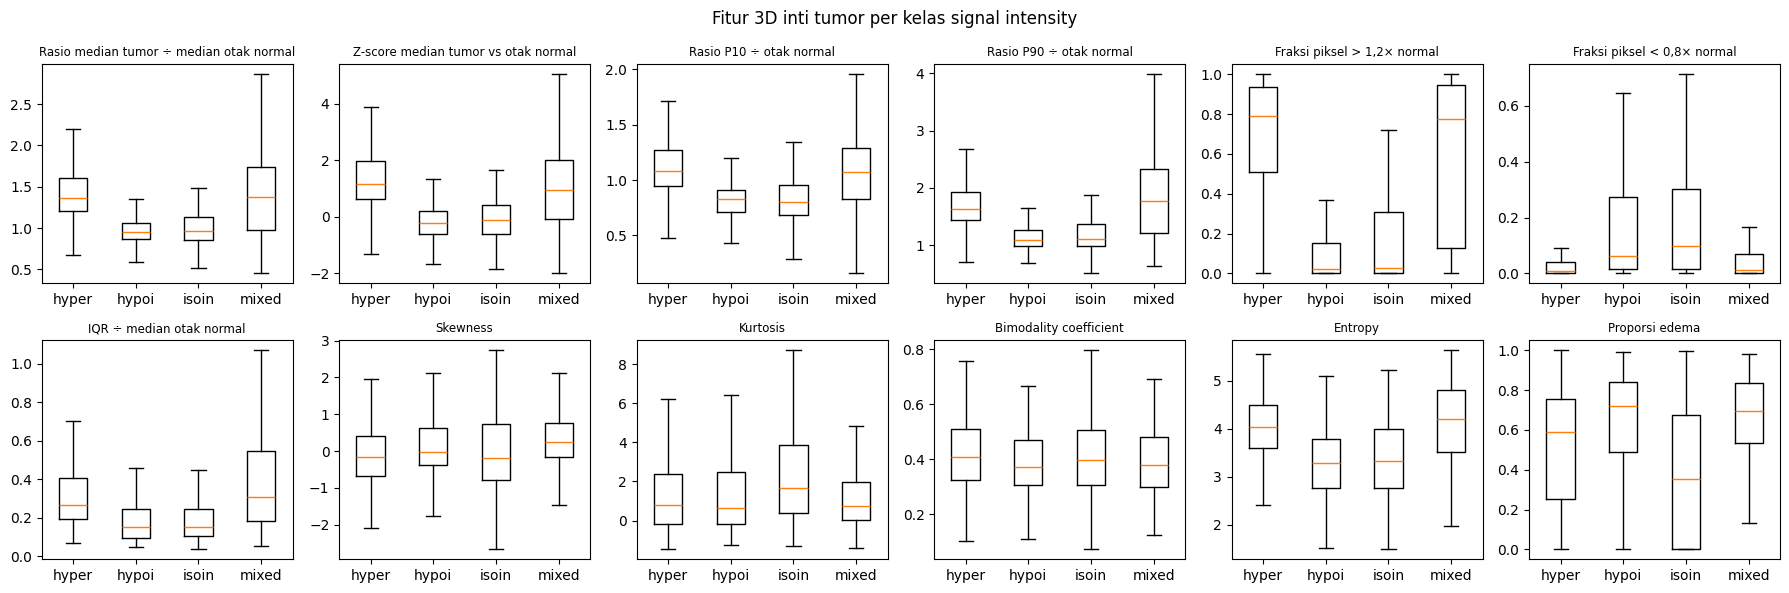

In [5]:
# Nilai tengah fitur tabel (inti tumor, 3D) per kelas: apakah fiturnya masuk akal?
_tab = FEAT["3d"][[f"inti__{s}" for s in STATS]].groupby(records.signal_label).median().T
_tab.index = [STAT_LABEL[s] for s in STATS]
print(_tab.round(2).to_string())

fig, axes = plt.subplots(2, 6, figsize=(18, 6)); axes = axes.ravel()
for ax, s in zip(axes, STATS + ["komposisi__frac_edema"]):
    col = f"inti__{s}" if s in STATS else s
    data = [FEAT["3d"].loc[records.signal_label == c, col].dropna().values for c in SIG_CLASSES]
    ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, 5)); ax.set_xticklabels([c[:5] for c in SIG_CLASSES])
    ax.set_title(STAT_LABEL.get(s, "Proporsi edema"), fontsize=8.5)
plt.suptitle("Fitur 3D inti tumor per kelas signal intensity"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "v5_fitur_boxplot.png"), dpi=140); plt.show()

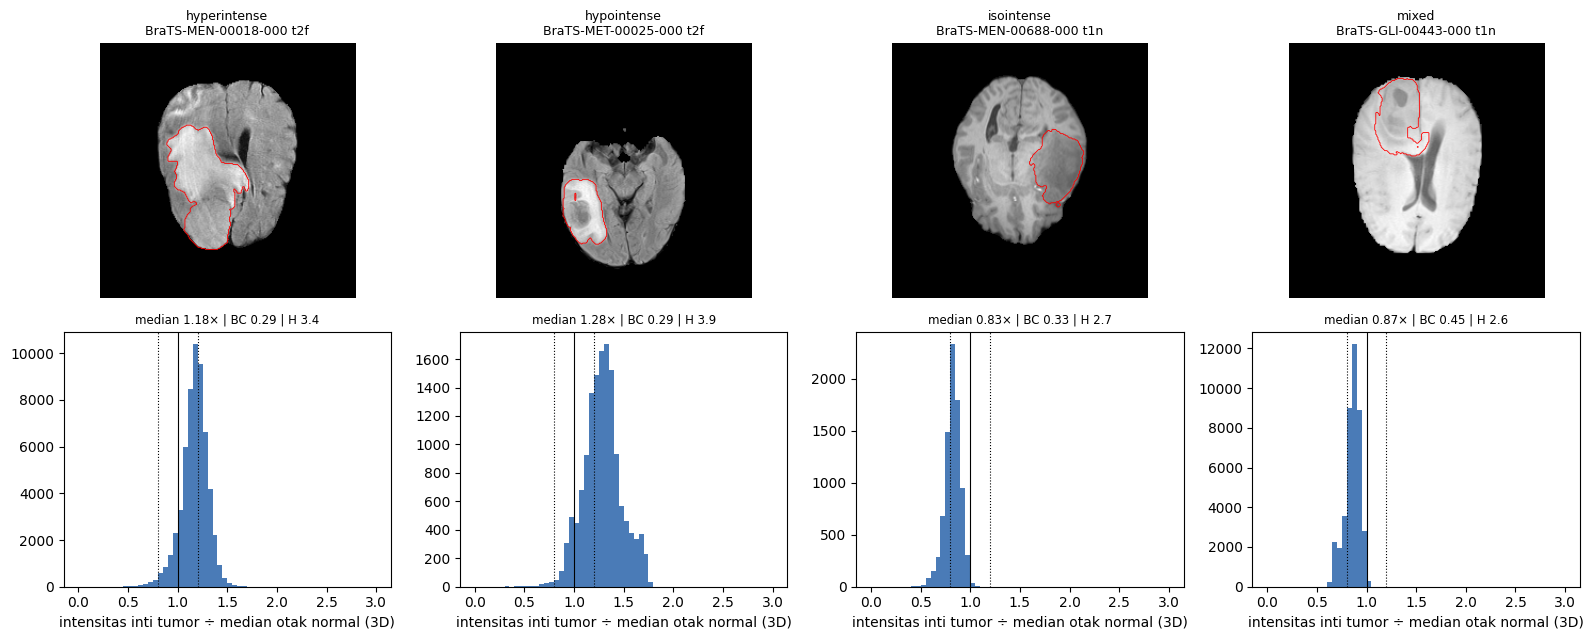

In [6]:
# Contoh histogram intensitas tumor (relatif terhadap otak normal) per kelas, seperti contoh dari pembimbing
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for j, c in enumerate(SIG_CLASSES):
    sub = records[(records.signal_label == c) & (records.split == "train")]
    r = sub.iloc[len(sub) // 3]
    k = SETS[(r.prefix, "old")][0]
    img, seg = VOL[r.prefix][r.modality][k], VOL[r.prefix]["seg"][k]
    ax = axes[0, j]; ax.imshow(img, cmap="gray"); ax.contour(seg > 0, levels=[0.5], colors="r", linewidths=0.6); ax.axis("off")
    ax.set_title(f"{c}\n{r.prefix} {r.modality}", fontsize=9)
    _, rc = intensity_features(r.prefix, r.modality, list(range(len(VOL[r.prefix]["slice_idx"]))))
    ax = axes[1, j]; ax.hist(np.clip(rc, 0, 3), bins=60, range=(0, 3), color="#4a7bb7")
    for x_, ls in [(0.8, ":"), (1.0, "-"), (1.2, ":")]:
        ax.axvline(x_, color="k", ls=ls, lw=0.8)
    f3 = FEAT["3d"].loc[r.name]
    ax.set_title(f"median {f3['inti__rasio_median']:.2f}× | BC {f3['inti__bimodality']:.2f} | H {f3['inti__entropy']:.1f}", fontsize=8.5)
    ax.set_xlabel("intensitas inti tumor ÷ median otak normal (3D)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_histogram_contoh.png"), dpi=140); plt.show()

## 4. Model fitur saja (tanpa gambar)

Logistic Regression, Random Forest, dan HistGradientBoosting, dengan fitur 2D / 3D, memakai **11 fitur tabel (inti tumor saja)**
atau **semua 70 fitur**. Satu-hot sequence ditambahkan karena arti terang/gelap berbeda per sequence. Dievaluasi di split tetap
(train → val/test) dan **5-fold CV per pasien** di train+val (fold sama dengan v3/v4).

In [7]:
SEQ_COLS = [f"seq_{m}" for m in MOD_CLASSES]
SEQ = pd.DataFrame({f"seq_{m}": (records.modality == m).astype(float) for m in MOD_CLASSES}, index=records.index)

trval = np.concatenate([split_idx["train"], split_idx["val"]])
pid = records.loc[trval, "prefix"].str.rsplit("-", n=1).str[0].values
FOLDS = []
for k, (a_, b_) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(trval, y_sig[trval], pid)):
    assert not (set(pid[a_]) & set(pid[b_]))
    FOLDS.append(dict(train=trval[a_], val=trval[b_], test=split_idx["test"]))

FEAT_MODELS = {
    "logreg": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                    LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)),
    "rf": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=0, n_jobs=-1)),
    "hgb": lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=200, class_weight="balanced", random_state=0),
}
FSETS = {"2d_tabel": ("2d", [f"inti__{s}" for s in STATS]), "3d_tabel": ("3d", [f"inti__{s}" for s in STATS]),
         "2d_all": ("2d", FEAT_COLS), "3d_all": ("3d", FEAT_COLS)}

def fmat(fset, with_seq=True):
    dim, cols = FSETS[fset]
    X = FEAT[dim][cols]
    return (pd.concat([X, SEQ], axis=1) if with_seq else X).values.astype(np.float64)

def macro_f1(y, p):
    return f1_score(y, p, average="macro", labels=list(range(len(SIG_CLASSES))), zero_division=0)

def eval_feat_model(fset, mname, store=False):
    X = fmat(fset)
    t0 = time.time(); m = FEAT_MODELS[mname]().fit(X[split_idx["train"]], y_sig[split_idx["train"]]); fit_s = time.time() - t0
    t0 = time.time(); Pt = m.predict_proba(X[split_idx["test"]]); pred_ms = (time.time() - t0) / len(split_idx["test"]) * 1000
    Pv = m.predict_proba(X[split_idx["val"]])
    cv, Pcv = [], []
    for fo in FOLDS:
        mm = FEAT_MODELS[mname]().fit(X[fo["train"]], y_sig[fo["train"]])
        cv.append(macro_f1(y_sig[fo["val"]], mm.predict(X[fo["val"]])))
        Pcv.append(dict(val=mm.predict_proba(X[fo["val"]]), test=mm.predict_proba(X[fo["test"]])))
    row = dict(fitur=fset, model=mname, n_fitur=X.shape[1] - len(SEQ_COLS),
               val_f1=macro_f1(y_sig[split_idx["val"]], Pv.argmax(1)), test_f1=macro_f1(y_sig[split_idx["test"]], Pt.argmax(1)),
               test_acc=accuracy_score(y_sig[split_idx["test"]], Pt.argmax(1)), cv_f1=np.mean(cv), cv_sd=np.std(cv),
               fit_s=fit_s, pred_ms=pred_ms)
    if store:
        FEAT_PRED[(fset, mname)] = dict(val=Pv, test=Pt, folds=Pcv)
    return row

FEAT_PRED = {}
fm_rows = [eval_feat_model(fs, mn, store=True) for fs in FSETS for mn in FEAT_MODELS]
fm_res = pd.DataFrame(fm_rows).round(3)
fm_res.to_csv(os.path.join(OUT_DIR, "v5_model_fitur.csv"), index=False)
fm_res.sort_values("cv_f1", ascending=False)

,fitur,model,n_fitur,val_f1,test_f1,test_acc,cv_f1,cv_sd,fit_s,pred_ms
7,2d_all,rf,70,0.604,0.581,0.620,0.593,0.010,0.907,0.520
11,3d_all,hgb,70,0.585,0.557,0.579,0.586,0.017,0.947,0.079
6,2d_all,logreg,70,0.572,0.577,0.591,0.584,0.038,0.040,0.009
10,3d_all,rf,70,0.582,0.565,0.591,0.583,0.023,0.953,0.517
9,3d_all,logreg,70,0.561,0.540,0.550,0.575,0.024,0.047,0.009
8,2d_all,hgb,70,0.594,0.570,0.596,0.575,0.033,0.996,0.079
1,2d_tabel,rf,11,0.540,0.405,0.427,0.522,0.019,0.800,0.510
0,2d_tabel,logreg,11,0.550,0.488,0.520,0.513,0.029,0.034,0.013
2,2d_tabel,hgb,11,0.584,0.505,0.509,0.512,0.023,0.494,0.080
3,3d_tabel,logreg,11,0.560,0.459,0.480,0.496,0.023,0.022,0.007


## 5. Ranking fitur: mana yang membantu, mana yang tidak

Dipakai model fitur terbaik (CV) dengan semua fitur. **Permutation importance per kelompok**: semua kolom satu kelompok diacak
bersamaan di fold validasi CV (10 ulangan × 5 fold), lalu dihitung turunnya macro-F1. Kelompok dibuat dua cara:
per **jenis statistik** (baris-baris tabel pembimbing, gabungan 6 area) dan per **area**.

Kriteria: **membantu** kalau rata-rata penurunan > 0 dan positif di ≥ 4 dari 5 fold; **tidak membantu** kalau rata-rata ≤ 0;
selain itu **lemah**. Semua ini hanya memakai train+val (test tidak dipakai untuk memilih fitur).

In [8]:
best_fm = fm_res[fm_res.fitur.str.endswith("_all")].sort_values("cv_f1", ascending=False).iloc[0]
RANK_DIM, RANK_MODEL = FSETS[best_fm.fitur][0], best_fm.model
print(f"Model untuk ranking: fitur {RANK_DIM.upper()} + {RANK_MODEL} (CV {best_fm.cv_f1:.3f})")
Xr = fmat(f"{RANK_DIM}_all"); cols_r = FEAT_COLS + SEQ_COLS
GROUPS_STAT = {s: [cols_r.index(f"{r}__{s}") for r in REGIONS] for s in STATS}
GROUPS_STAT["komposisi"] = [cols_r.index(c) for c in KOMPOSISI]
GROUPS_REG = {r: [cols_r.index(f"{r}__{s}") for s in STATS] for r in REGIONS}
GROUPS_REG["komposisi"] = GROUPS_STAT["komposisi"]
GROUPS_IND = {c: [cols_r.index(c)] for c in FEAT_COLS}

def perm_importance(groups, n_rep=10, seed=0):
    rng = np.random.default_rng(seed); res = {g: [] for g in groups}
    for fo in FOLDS:
        m = FEAT_MODELS[RANK_MODEL]().fit(Xr[fo["train"]], y_sig[fo["train"]])
        Xv, yv = Xr[fo["val"]], y_sig[fo["val"]]; base = macro_f1(yv, m.predict(Xv))
        for g, idx in groups.items():
            d = []
            for _ in range(n_rep):
                Xp = Xv.copy(); perm = rng.permutation(len(Xv)); Xp[:, idx] = Xv[perm][:, idx]
                d.append(base - macro_f1(yv, m.predict(Xp)))
            res[g].append(np.mean(d))
    out = pd.DataFrame({"penurunan_f1": {g: np.mean(v) for g, v in res.items()}, "sd_fold": {g: np.std(v) for g, v in res.items()},
                        "fold_positif": {g: int(np.sum(np.array(v) > 0)) for g, v in res.items()}})
    out["status"] = np.where(out.penurunan_f1 <= 0, "tidak membantu", np.where(out.fold_positif >= 4, "membantu", "lemah"))
    return out.sort_values("penurunan_f1", ascending=False)

t0 = time.time()
rank_stat = perm_importance(GROUPS_STAT); rank_reg = perm_importance(GROUPS_REG)
rank_ind = perm_importance(GROUPS_IND, n_rep=5)
mi = pd.Series(mutual_info_classif(SimpleImputer(strategy="median").fit_transform(Xr[trval][:, :len(FEAT_COLS)]), y_sig[trval],
                                   random_state=0), index=FEAT_COLS)
rank_ind["mutual_info"] = mi.reindex(rank_ind.index)
rank_stat.insert(0, "fitur", [STAT_LABEL[s] for s in rank_stat.index])
print(f"Ranking selesai ({time.time() - t0:.0f}s)")
rank_stat.to_csv(os.path.join(OUT_DIR, "v5_ranking_statistik.csv")); rank_reg.to_csv(os.path.join(OUT_DIR, "v5_ranking_area.csv"))
rank_ind.to_csv(os.path.join(OUT_DIR, "v5_ranking_individu.csv"))
print("\nPer jenis statistik (baris tabel pembimbing):"); print(rank_stat.round(4).to_string())
print("\nPer area:"); print(rank_reg.round(4).to_string())
print("\n15 fitur individu teratas:"); print(rank_ind.head(15).round(4).to_string())

Model untuk ranking: fitur 2D + rf (CV 0.593)
Ranking selesai (261s)

Per jenis statistik (baris tabel pembimbing):
                                                 fitur  penurunan_f1  sd_fold  fold_positif          status
komposisi      Komposisi (proporsi NCR/edema/ET, luas)        0.0352   0.0157             5        membantu
rasio_median   Rasio median tumor ÷ median otak normal        0.0129   0.0064             5        membantu
frac_terang                Fraksi piksel > 1,2× normal        0.0126   0.0106             5        membantu
rasio_p90                      Rasio P90 ÷ otak normal        0.0125   0.0106             5        membantu
zscore_median      Z-score median tumor vs otak normal        0.0114   0.0022             5        membantu
entropy                                        Entropy        0.0107   0.0185             3           lemah
skewness                                      Skewness        0.0099   0.0189             4        membantu
iqr_rel             

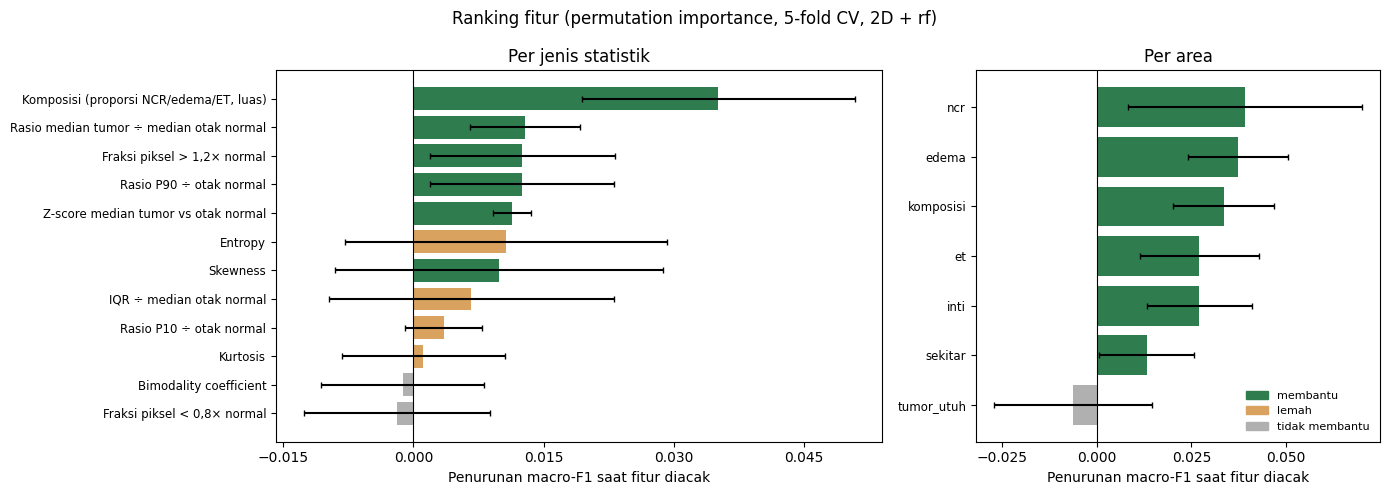

In [9]:
COLOR = {"membantu": "#2f7d4f", "lemah": "#d9a25f", "tidak membantu": "#b0b0b0"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.5, 1]))
for ax, rk, labels, title in [(axes[0], rank_stat, rank_stat.fitur, "Per jenis statistik"),
                              (axes[1], rank_reg, rank_reg.index, "Per area")]:
    rk_ = rk.iloc[::-1]; lab = list(labels)[::-1]
    ax.barh(range(len(rk_)), rk_.penurunan_f1, xerr=rk_.sd_fold, color=[COLOR[s] for s in rk_.status], capsize=2)
    ax.set_yticks(range(len(rk_))); ax.set_yticklabels(lab, fontsize=8.5); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("Penurunan macro-F1 saat fitur diacak"); ax.set_title(title)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR.values()]
axes[1].legend(handles, COLOR.keys(), frameon=False, fontsize=8, loc="lower right")
plt.suptitle(f"Ranking fitur (permutation importance, 5-fold CV, {RANK_DIM.upper()} + {RANK_MODEL})")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_ranking_fitur.png"), dpi=150); plt.show()

In [10]:
# Fitur terpilih = jenis statistik yang tidak "tidak membantu" × area yang tidak "tidak membantu"
keep_stat = [s for s in rank_stat.index if rank_stat.loc[s, "status"] != "tidak membantu"]
keep_reg = [r for r in rank_reg.index if rank_reg.loc[r, "status"] != "tidak membantu"]
SEL_COLS = [f"{r}__{s}" for r in REGIONS for s in STATS if r in keep_reg and s in keep_stat]
if "komposisi" in keep_stat and "komposisi" in keep_reg:
    SEL_COLS += KOMPOSISI
FSETS[f"{RANK_DIM}_terpilih"] = (RANK_DIM, SEL_COLS)
print(f"Fitur terpilih: {len(SEL_COLS)} dari {len(FEAT_COLS)}")
print("  statistik:", keep_stat); print("  area:", keep_reg)
for mn in FEAT_MODELS:
    fm_rows.append(eval_feat_model(f"{RANK_DIM}_terpilih", mn, store=True))
fm_res = pd.DataFrame(fm_rows).round(3)
fm_res.to_csv(os.path.join(OUT_DIR, "v5_model_fitur.csv"), index=False)
fm_res[fm_res.fitur.str.startswith(RANK_DIM)].sort_values("cv_f1", ascending=False)

Fitur terpilih: 49 dari 70
  statistik: ['komposisi', 'rasio_median', 'frac_terang', 'rasio_p90', 'zscore_median', 'entropy', 'skewness', 'iqr_rel', 'rasio_p10', 'kurtosis']
  area: ['ncr', 'edema', 'komposisi', 'et', 'inti', 'sekitar']


,fitur,model,n_fitur,val_f1,test_f1,test_acc,cv_f1,cv_sd,fit_s,pred_ms
13,2d_terpilih,rf,49,0.627,0.591,0.626,0.599,0.012,0.872,0.521
12,2d_terpilih,logreg,49,0.564,0.524,0.550,0.596,0.036,0.029,0.008
7,2d_all,rf,70,0.604,0.581,0.620,0.593,0.010,0.907,0.520
6,2d_all,logreg,70,0.572,0.577,0.591,0.584,0.038,0.040,0.009
14,2d_terpilih,hgb,49,0.508,0.581,0.602,0.580,0.015,0.804,0.080
8,2d_all,hgb,70,0.594,0.570,0.596,0.575,0.033,0.996,0.079
1,2d_tabel,rf,11,0.540,0.405,0.427,0.522,0.019,0.800,0.510
0,2d_tabel,logreg,11,0.550,0.488,0.520,0.513,0.029,0.034,0.013
2,2d_tabel,hgb,11,0.584,0.505,0.509,0.512,0.023,0.494,0.080


## 6. Model deep learning: 2D single slice, 2D multislice, 3D, dan hybrid (fitur masuk ke head)

| Eksperimen | Input gambar | Fitur di head |
|---|---|---|
| `2D single slice` (baseline v3/v4) | 1 slice (slice lama), ViT-S | – |
| `2D multislice` | win4 (±4 slice, maks 9), ViT-S, prob dirata-rata | – |
| `3D` | 16 slice seluruh tumor, ROI 112×112, R3D-18 pretrained Kinetics-400 | – |
| `Hybrid + fitur 2D/3D/terpilih` | 1 slice (slice lama), ViT-S | 70 fitur (atau fitur terpilih) → MLP 64 → digabung ke head signal |

Head signal menerima: embedding gambar + softmax sequence + embedding fitur. Fitur distandarisasi dengan mean/sd data train.

In [11]:
def make_view(img, mask, bbox, cfg, rng=None, out=IMG_SIZE, flip=None):
    H, W = img.shape
    aug = rng is not None
    y0, y1, x0, x1 = bbox
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    side = float(np.clip(max(y1 - y0 + 1, x1 - x0 + 1) * cfg["roi_margin"], cfg["roi_min"], max(H, W)))
    theta, do_flip = 0.0, False
    if aug:
        side *= rng.uniform(0.85, 1.2)
        cy += rng.uniform(-0.12, 0.12) * side
        cx += rng.uniform(-0.12, 0.12) * side
        theta = np.deg2rad(rng.uniform(-15, 15))
        do_flip = rng.random() < 0.5
    if flip is not None:
        do_flip = flip
    k = side / out
    R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    A = k * R @ np.diag([-1.0 if do_flip else 1.0, 1.0])
    b = np.array([cx, cy]) - A @ np.array([out / 2, out / 2])
    M = np.hstack([A, b[:, None]]).astype(np.float32)
    im = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP, borderValue=0)
    ms = cv2.warpAffine(mask, M, (out, out), flags=cv2.INTER_NEAREST | cv2.WARP_INVERSE_MAP, borderValue=0)
    if aug and cfg.get("elastic", False) and rng.random() < 0.5:
        alpha, sigma = out * 0.03, out * 0.06
        dx = cv2.GaussianBlur(rng.uniform(-1, 1, (out, out)).astype(np.float32), (0, 0), sigma)
        dy = cv2.GaussianBlur(rng.uniform(-1, 1, (out, out)).astype(np.float32), (0, 0), sigma)
        dx *= alpha / (np.abs(dx).max() + 1e-6); dy *= alpha / (np.abs(dy).max() + 1e-6)
        gx, gy = np.meshgrid(np.arange(out, dtype=np.float32), np.arange(out, dtype=np.float32))
        im = cv2.remap(im, gx + dx, gy + dy, cv2.INTER_LINEAR, borderValue=0)
        ms = cv2.remap(ms, gx + dx, gy + dy, cv2.INTER_NEAREST, borderValue=0)
    return im.astype(np.float32) / 255.0, ms

def bbox_of(mask):
    ys, xs = np.where(mask > 0)
    return ys.min(), ys.max(), xs.min(), xs.max()

def to_channels(im, ms, n_gray=3):
    g = (im - 0.5) / 0.25
    core = ((ms == 1) | (ms == 3)).astype(np.float32) * 2 - 1
    edema = (ms == 2).astype(np.float32) * 2 - 1
    return np.stack([g] * n_gray + [core, edema], 0).astype(np.float32)

def input_2d(i, k, rng=None, flip=None):
    r = records.iloc[i]; v = VOL[r.prefix]
    im, ms = make_view(v[r.modality][k], v["seg"][k], bbox_of(v["seg"][k]), CFG, rng=rng, flip=flip)
    return to_channels(im, ms)                                               # (5, 224, 224)

def input_3d(i, rng=None, flip=None):
    r = records.iloc[i]; v = VOL[r.prefix]; ks = vol_ks(r.prefix)
    bb = bbox_of(v["seg"][ks].max(0))                                        # bbox gabungan semua slice
    seed = None if rng is None else int(rng.integers(1 << 31))
    out = []
    for k in ks:                                                            # augmentasi sama untuk semua slice
        im, ms = make_view(v[r.modality][k], v["seg"][k], bb, CFG3D,
                           rng=None if seed is None else np.random.default_rng(seed), out=VOL_SIZE, flip=flip)
        out.append(to_channels(im, ms, n_gray=1))
    return np.stack(out, 1)                                                  # (3, D, 112, 112)

In [12]:
class FeatStore:
    """Fitur per record, distandarisasi dengan mean/sd data train dari split yang sedang dipakai."""
    def __init__(self, fset, train_idx):
        dim, cols = FSETS[fset]
        X = FEAT[dim][cols].values.astype(np.float32)
        mu, sd = np.nanmean(X[train_idx], 0), np.nanstd(X[train_idx], 0) + 1e-6
        self.mu, self.sd = np.nan_to_num(mu), np.nan_to_num(sd, nan=1.0)
        self.X = self.transform(X)
        self.cols = cols
    def transform(self, X):
        return np.nan_to_num(np.clip((X - self.mu) / self.sd, -5, 5), nan=0.0).astype(np.float32)
    def __getitem__(self, i):
        return self.X[i]

class TrainDS(Dataset):
    def __init__(self, exp, idx, fs):
        self.exp, self.idx, self.fs = exp, np.asarray(idx), fs
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, j):
        i = int(self.idx[j]); rng = np.random.default_rng(); r = records.iloc[i]
        if self.exp["arch"] == "r3d":
            x = input_3d(i, rng=rng)
        else:
            x = input_2d(i, int(rng.choice(SETS[(r.prefix, self.exp["train"])])), rng=rng)
        f = self.fs[i] if self.fs is not None else np.zeros(1, np.float32)
        return torch.from_numpy(x), torch.from_numpy(f), int(r.mod_y), int(r.sig_y)

class EvalDS(Dataset):
    def __init__(self, exp, idx, fs, flip=False):
        self.exp, self.fs, self.flip = exp, fs, flip
        if exp["arch"] == "r3d":
            self.items = [(int(i), None) for i in idx]
        else:
            self.items = [(int(i), k) for i in idx for k in SETS[(records.prefix[i], exp["eval"])]]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, j):
        i, k = self.items[j]
        x = input_3d(i, flip=self.flip) if k is None else input_2d(i, k, flip=self.flip)
        f = self.fs[i] if self.fs is not None else np.zeros(1, np.float32)
        return torch.from_numpy(x), torch.from_numpy(f), i

def worker_init(wid):
    np.random.seed((torch.initial_seed() + wid) % 2**32)

In [13]:
class Net(nn.Module):
    def __init__(self, arch, n_feat=0):
        super().__init__()
        self.arch, self.n_feat = arch, n_feat
        if arch == "vit":
            self.backbone = timm.create_model(CFG["backbone"], pretrained=True, num_classes=0, in_chans=5, drop_path_rate=0.1)
            d = self.backbone.num_features
        else:
            from torchvision.models.video import r3d_18
            try:
                from torchvision.models.video import R3D_18_Weights
                self.backbone = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
            except Exception as e:
                print("Bobot Kinetics gagal diunduh, R3D-18 dari awal:", e)
                self.backbone = r3d_18(weights=None)
            d = self.backbone.fc.in_features
            self.backbone.fc = nn.Identity()
        self.drop = nn.Dropout(CFG["dropout"])
        self.mod_head = nn.Linear(d, len(MOD_CLASSES))
        extra = len(MOD_CLASSES)
        if n_feat:
            self.feat = nn.Sequential(nn.Linear(n_feat, CFG["feat_dim"]), nn.GELU(), nn.Dropout(CFG["feat_dropout"]))
            extra += CFG["feat_dim"]
        self.sig_head = nn.Sequential(nn.Linear(d + extra, 256), nn.GELU(), nn.Dropout(CFG["dropout"]),
                                      nn.Linear(256, len(SIG_CLASSES)))
    def embed(self, x):
        if self.arch == "vit":
            z = self.backbone.forward_head(self.backbone.forward_features(x), pre_logits=True)
        else:
            z = self.backbone(x)
        return self.drop(z)
    def head(self, z, ml, f=None):
        parts = [z, ml.softmax(1)]
        if self.n_feat:
            parts.append(self.feat(f))
        return self.sig_head(torch.cat(parts, 1))
    def forward(self, x, f=None):
        z = self.embed(x); ml = self.mod_head(z)
        return ml, self.head(z, ml, f)

def make_sig_loss(train_idx):
    counts = np.bincount(y_sig[train_idx], minlength=len(SIG_CLASSES)).astype(np.float32)
    w = 1 / np.sqrt(np.maximum(counts, 1)); w = w / w.mean()
    return nn.CrossEntropyLoss(weight=torch.tensor(w, device=DEVICE), label_smoothing=CFG["label_smoothing"])

## 7. Training, evaluasi, dan pengukuran runtime (resumable per run)

Untuk setiap run dicatat: lama training, jumlah epoch, detik per epoch, memori GPU puncak, jumlah parameter, dan
**waktu inferensi per pasien** (1 pass tanpa TTA, termasuk menyiapkan input).

In [14]:
AMP = dict(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda")

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def predict_records(model, exp, idx, fs, tta=True):
    model.eval()
    acc_s = {int(i): [] for i in idx}; acc_m = {int(i): [] for i in idx}
    bs = 16 if exp["arch"] == "r3d" else 128
    for flip in ([False, True] if tta else [False]):
        dl = DataLoader(EvalDS(exp, idx, fs, flip), batch_size=bs, shuffle=False, num_workers=2)
        for x, f, ii in dl:
            with torch.autocast(**AMP):
                ml, sl = model(x.to(DEVICE, non_blocking=True), f.to(DEVICE))
            ps, pm = sl.float().softmax(1).cpu().numpy(), ml.float().softmax(1).cpu().numpy()
            for j, i in enumerate(ii.numpy()):
                acc_s[int(i)].append(ps[j]); acc_m[int(i)].append(pm[j])
    return (np.stack([np.mean(acc_s[int(i)], 0) for i in idx]), np.stack([np.mean(acc_m[int(i)], 0) for i in idx]))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_key(exp, seed):
    return f"{exp['key']}__seed={seed}"

def ckpt_path(key):
    return os.path.join(CKPT_DIR, key + ".pt")

def build_model(exp, fs):
    return Net(exp["arch"], n_feat=len(fs.cols) if fs is not None else 0).to(DEVICE)

def train_run(exp, seed, split=None, tag="", verbose=False, save_ckpt=None):
    sp = split or split_idx
    key = run_key(exp, seed) + tag
    save_ckpt = (tag == "") if save_ckpt is None else save_ckpt
    path = os.path.join(RUNS_DIR, key + ".json")
    fs = FeatStore(exp["fset"], sp["train"]) if exp.get("fset") else None
    if os.path.exists(path) and (not save_ckpt or os.path.exists(ckpt_path(key))):
        out = json.load(open(path))
        if out.get("feat_cols") == (fs.cols if fs else None):
            return out
    cfg = CFG3D if exp["arch"] == "r3d" else CFG
    set_seed(seed)
    dl = DataLoader(TrainDS(exp, sp["train"], fs), batch_size=cfg["batch_size"], shuffle=True,
                    num_workers=2, drop_last=True, worker_init_fn=worker_init, pin_memory=True)
    model = build_model(exp, fs)
    n_params = sum(p.numel() for p in model.parameters())
    bb = list(model.backbone.parameters())
    head = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    opt = torch.optim.AdamW([dict(params=bb, lr=cfg["lr_backbone"], weight_decay=cfg["wd"]),
                             dict(params=head, lr=cfg["lr_head"], weight_decay=1e-4)])
    spe = len(dl); total, warm = cfg["epochs"] * spe, cfg["warmup_epochs"] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                              else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    crit_m = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]); crit_s = make_sig_loss(sp["train"])
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best, best_state, bad, hist, train_sec = -1, None, 0, [], 0.0
    t_all = time.time()
    for ep in range(cfg["epochs"]):
        model.train(); tl = 0.0; sync(); te = time.time()
        for x, f, ym, ys in dl:
            x, f, ym, ys = x.to(DEVICE, non_blocking=True), f.to(DEVICE), ym.to(DEVICE), ys.to(DEVICE)
            with torch.autocast(**AMP):
                ml, sl = model(x, f)
                loss = cfg["w_modality"] * crit_m(ml.float(), ym) + cfg["w_signal"] * crit_s(sl.float(), ys)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item()
        sync(); train_sec += time.time() - te
        Ps, _ = predict_records(model, exp, sp["val"], fs, tta=False)
        vf1 = macro_f1(y_sig[sp["val"]], Ps.argmax(1))
        hist.append(dict(epoch=ep + 1, loss=tl / spe, val_f1=vf1))
        if verbose:
            print(f"  ep {ep + 1:2d} loss={tl / spe:.3f} val_f1={vf1:.3f}")
        if vf1 > best:
            best, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    minutes = (time.time() - t_all) / 60
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan")
    model.load_state_dict(best_state)
    if save_ckpt:
        torch.save(best_state, ckpt_path(key))
    sync(); t0 = time.time()
    predict_records(model, exp, sp["test"], fs, tta=False); sync()
    infer_ms = (time.time() - t0) / len(sp["test"]) * 1000
    out = dict(key=key, exp=exp["key"], seed=seed, history=hist, minutes=minutes, epochs=len(hist),
               sec_per_epoch=train_sec / len(hist), peak_mb=peak_mb, n_params=n_params, infer_ms=infer_ms,
               feat_cols=fs.cols if fs else None, eval={})
    for s in ["val", "test"]:
        Ps, Pm = predict_records(model, exp, sp[s], fs, tta=CFG["tta"])
        out["eval"][s] = dict(p_sig=Ps.tolist(), p_mod=Pm.tolist(), idx=[int(i) for i in sp[s]],
                              sig_f1=macro_f1(y_sig[sp[s]], Ps.argmax(1)), sig_acc=accuracy_score(y_sig[sp[s]], Ps.argmax(1)),
                              mod_acc=accuracy_score(y_mod[sp[s]], Pm.argmax(1)))
    json.dump(out, open(path, "w"))
    print(f"{key}: {len(hist)} ep, {minutes:.1f} min, {out['sec_per_epoch']:.0f} s/ep, infer {infer_ms:.1f} ms/pasien | "
          f"val {out['eval']['val']['sig_f1']:.3f} test {out['eval']['test']['sig_f1']:.3f}")
    del model; torch.cuda.empty_cache()
    return out

In [15]:
EXPS = {
    "2D single slice":        dict(key="vit_old",        arch="vit", train="old",  eval="old",  fset=None),
    "2D multislice (win4)":   dict(key="vit_win4",       arch="vit", train="win4", eval="win4", fset=None),
    "3D (R3D-18)":            dict(key="r3d",            arch="r3d", fset=None),
    "Hybrid + fitur 2D":      dict(key="vit_old+2d_all", arch="vit", train="old",  eval="old",  fset="2d_all"),
    "Hybrid + fitur 3D":      dict(key="vit_old+3d_all", arch="vit", train="old",  eval="old",  fset="3d_all"),
    f"Hybrid + fitur {RANK_DIM.upper()} terpilih": dict(key=f"vit_old+{RANK_DIM}_terpilih", arch="vit", train="old", eval="old",
                                                        fset=f"{RANK_DIM}_terpilih"),
}

In [16]:
# Smoke test 2 epoch untuk tiap jenis model (error ketahuan dalam beberapa menit)
_ep, _ep3 = CFG["epochs"], CFG3D["epochs"]; CFG["epochs"] = CFG3D["epochs"] = 2
_small = dict(train=split_idx["train"][:64], val=split_idx["val"][:32], test=split_idx["test"][:32])
for name in ["2D multislice (win4)", "3D (R3D-18)", "Hybrid + fitur 3D"]:
    _o = train_run(EXPS[name], 0, split=_small, tag="__smoke", verbose=True, save_ckpt=False)
    os.remove(os.path.join(RUNS_DIR, _o["key"] + ".json"))
CFG["epochs"], CFG3D["epochs"] = _ep, _ep3
print("Smoke test OK")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep  1 loss=2.219 val_f1=0.166
  ep  2 loss=1.817 val_f1=0.209
vit_win4__seed=0__smoke: 2 ep, 0.1 min, 2 s/ep, infer 29.8 ms/pasien | val 0.209 test 0.167
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 206MB/s]


  ep  1 loss=1.747 val_f1=0.209
  ep  2 loss=1.545 val_f1=0.209
r3d__seed=0__smoke: 2 ep, 0.1 min, 2 s/ep, infer 17.5 ms/pasien | val 0.209 test 0.167
  ep  1 loss=1.884 val_f1=0.209
  ep  2 loss=1.718 val_f1=0.209
vit_old+3d_all__seed=0__smoke: 2 ep, 0.0 min, 1 s/ep, infer 10.4 ms/pasien | val 0.213 test 0.167
Smoke test OK


## 8. Eksperimen utama (3 seed per eksperimen)

In [17]:
ALL_RUNS = {name: [train_run(exp, s) for s in SEEDS] for name, exp in EXPS.items()}

def ens(runs, s):
    return np.mean([np.array(r["eval"][s]["p_sig"]) for r in runs], 0)

rows = []
for name, runs in ALL_RUNS.items():
    Pv, Pt = ens(runs, "val"), ens(runs, "test")
    rows.append(dict(eksperimen=name, jenis="deep",
                     val_f1=np.mean([r["eval"]["val"]["sig_f1"] for r in runs]), val_sd=np.std([r["eval"]["val"]["sig_f1"] for r in runs]),
                     test_f1=np.mean([r["eval"]["test"]["sig_f1"] for r in runs]), test_sd=np.std([r["eval"]["test"]["sig_f1"] for r in runs]),
                     ens_val_f1=macro_f1(y_sig[split_idx["val"]], Pv.argmax(1)), ens_test_f1=macro_f1(y_sig[split_idx["test"]], Pt.argmax(1)),
                     ens_test_acc=accuracy_score(y_sig[split_idx["test"]], Pt.argmax(1)),
                     seq_acc=np.mean([r["eval"]["test"]["mod_acc"] for r in runs])))
deep_res = pd.DataFrame(rows).round(3)
deep_res

vit_old__seed=42: 29 ep, 1.8 min, 3 s/ep, infer 5.0 ms/pasien | val 0.681 test 0.592
vit_old__seed=1337: 18 ep, 1.2 min, 3 s/ep, infer 4.9 ms/pasien | val 0.691 test 0.554
vit_old__seed=2024: 17 ep, 1.1 min, 3 s/ep, infer 4.9 ms/pasien | val 0.662 test 0.564
vit_win4__seed=42: 25 ep, 2.4 min, 3 s/ep, infer 16.6 ms/pasien | val 0.665 test 0.615
vit_win4__seed=1337: 18 ep, 1.7 min, 3 s/ep, infer 16.8 ms/pasien | val 0.685 test 0.543
vit_win4__seed=2024: 27 ep, 2.6 min, 3 s/ep, infer 16.6 ms/pasien | val 0.655 test 0.614
r3d__seed=42: 24 ep, 7.3 min, 17 s/ep, infer 9.1 ms/pasien | val 0.658 test 0.562
r3d__seed=1337: 30 ep, 9.1 min, 17 s/ep, infer 9.1 ms/pasien | val 0.633 test 0.573
r3d__seed=2024: 30 ep, 9.1 min, 17 s/ep, infer 9.2 ms/pasien | val 0.625 test 0.606
vit_old+2d_all__seed=42: 25 ep, 1.6 min, 3 s/ep, infer 5.0 ms/pasien | val 0.656 test 0.556
vit_old+2d_all__seed=1337: 21 ep, 1.4 min, 3 s/ep, infer 4.9 ms/pasien | val 0.732 test 0.597
vit_old+2d_all__seed=2024: 26 ep, 1.7 mi

,eksperimen,jenis,val_f1,val_sd,test_f1,test_sd,ens_val_f1,ens_test_f1,ens_test_acc,seq_acc
0,2D single slice,deep,0.678,0.012,0.570,0.016,0.710,0.601,0.620,0.984
1,2D multislice (win4),deep,0.668,0.012,0.591,0.033,0.679,0.639,0.655,0.994
2,3D (R3D-18),deep,0.639,0.014,0.580,0.019,0.672,0.566,0.591,0.990
3,Hybrid + fitur 2D,deep,0.682,0.036,0.590,0.025,0.685,0.585,0.602,0.971
4,Hybrid + fitur 3D,deep,0.660,0.010,0.564,0.033,0.681,0.589,0.602,0.982
5,Hybrid + fitur 2D terpilih,deep,0.658,0.012,0.565,0.053,0.664,0.611,0.637,0.979


## 9. Late fusion: probabilitas model gambar + model fitur

`P = w · P_gambar + (1 − w) · P_fitur`, bobot `w` dipilih dari **log-loss di val** (lebih stabil dari F1 untuk 163 data).
Model fitur yang dipakai = model terbaik (CV) untuk masing-masing fitur 2D / 3D / terpilih.

In [18]:
def best_feat_model(prefix):
    sub = fm_res[fm_res.fitur.str.startswith(prefix)].sort_values("cv_f1", ascending=False).iloc[0]
    return sub.fitur, sub.model

def fuse(Pa, Pb, w):
    return w * Pa + (1 - w) * Pb

def pick_w(Pa_v, Pb_v):
    ws = np.round(np.arange(0, 1.0001, 0.05), 2)
    return float(ws[np.argmin([log_loss(y_sig[split_idx["val"]], fuse(Pa_v, Pb_v, w), labels=range(4)) for w in ws])])

FUSIONS = {}
fu_rows = []
for deep_name in ["2D single slice", max([n for n in EXPS if n.startswith("Hybrid")], key=lambda n: deep_res.set_index("eksperimen").loc[n, "ens_val_f1"])]:
    for fp in ["2d_", "3d_", f"{RANK_DIM}_terpilih"]:
        fset, mname = best_feat_model(fp)
        Pa_v, Pa_t = ens(ALL_RUNS[deep_name], "val"), ens(ALL_RUNS[deep_name], "test")
        Pb_v, Pb_t = FEAT_PRED[(fset, mname)]["val"], FEAT_PRED[(fset, mname)]["test"]
        w = pick_w(Pa_v, Pb_v)
        name = f"Fusion: {deep_name} + {fset} ({mname})"
        FUSIONS[name] = dict(deep=deep_name, fset=fset, model=mname, w=w)
        Pv, Pt = fuse(Pa_v, Pb_v, w), fuse(Pa_t, Pb_t, w)
        fu_rows.append(dict(eksperimen=name, jenis="fusion", w_gambar=w,
                            ens_val_f1=macro_f1(y_sig[split_idx["val"]], Pv.argmax(1)),
                            ens_test_f1=macro_f1(y_sig[split_idx["test"]], Pt.argmax(1)),
                            ens_test_acc=accuracy_score(y_sig[split_idx["test"]], Pt.argmax(1))))
fu_res = pd.DataFrame(fu_rows).drop_duplicates("eksperimen").round(3)
fu_res

,eksperimen,jenis,w_gambar,ens_val_f1,ens_test_f1,ens_test_acc
0,Fusion: 2D single slice + 2d_terpilih (rf),fusion,0.80,0.703,0.580,0.608
1,Fusion: 2D single slice + 3d_all (hgb),fusion,0.65,0.660,0.611,0.637
3,Fusion: Hybrid + fitur 2D + 2d_terpilih (rf),fusion,0.80,0.704,0.589,0.614
4,Fusion: Hybrid + fitur 2D + 3d_all (hgb),fusion,0.65,0.682,0.626,0.661


## 10. Perbandingan semua pendekatan

In [19]:
fm_best = []
for fp in ["2d_tabel", "3d_tabel", "2d_all", "3d_all", f"{RANK_DIM}_terpilih"]:
    r = fm_res[fm_res.fitur == fp].sort_values("cv_f1", ascending=False).iloc[0]
    fm_best.append(dict(eksperimen=f"Fitur saja: {fp} ({r.model})", jenis="fitur", val_f1=r.val_f1, ens_val_f1=r.val_f1,
                        test_f1=r.test_f1, ens_test_f1=r.test_f1, ens_test_acc=r.test_acc, cv_f1=r.cv_f1, cv_sd=r.cv_sd))
compare = pd.concat([deep_res, fu_res, pd.DataFrame(fm_best)], ignore_index=True)
compare["capai_0.65"] = np.where(compare.ens_test_f1 >= TARGET_F1, "ya", "belum")
compare = compare.sort_values("ens_val_f1", ascending=False).reset_index(drop=True)
compare.to_csv(os.path.join(OUT_DIR, "v5_perbandingan.csv"), index=False)
print("Kolom ens_* = ensemble 3 seed (untuk fitur saja: 1 model). Diurutkan berdasarkan val.")
compare[["eksperimen", "jenis", "val_f1", "ens_val_f1", "test_f1", "test_sd", "ens_test_f1", "ens_test_acc", "seq_acc", "capai_0.65"]]

Kolom ens_* = ensemble 3 seed (untuk fitur saja: 1 model). Diurutkan berdasarkan val.


,eksperimen,jenis,val_f1,ens_val_f1,test_f1,test_sd,ens_test_f1,ens_test_acc,seq_acc,capai_0.65
0,2D single slice,deep,0.678,0.710,0.570,0.016,0.601,0.620,0.984,belum
1,Fusion: Hybrid + fitur 2D + 2d_terpilih (rf),fusion,NaN,0.704,NaN,NaN,0.589,0.614,NaN,belum
2,Fusion: 2D single slice + 2d_terpilih (rf),fusion,NaN,0.703,NaN,NaN,0.580,0.608,NaN,belum
3,Hybrid + fitur 2D,deep,0.682,0.685,0.590,0.025,0.585,0.602,0.971,belum
4,Fusion: Hybrid + fitur 2D + 3d_all (hgb),fusion,NaN,0.682,NaN,NaN,0.626,0.661,NaN,belum
5,Hybrid + fitur 3D,deep,0.660,0.681,0.564,0.033,0.589,0.602,0.982,belum
6,2D multislice (win4),deep,0.668,0.679,0.591,0.033,0.639,0.655,0.994,belum
7,3D (R3D-18),deep,0.639,0.672,0.580,0.019,0.566,0.591,0.990,belum
8,Hybrid + fitur 2D terpilih,deep,0.658,0.664,0.565,0.053,0.611,0.637,0.979,belum
9,Fusion: 2D single slice + 3d_all (hgb),fusion,NaN,0.660,NaN,NaN,0.611,0.637,NaN,belum


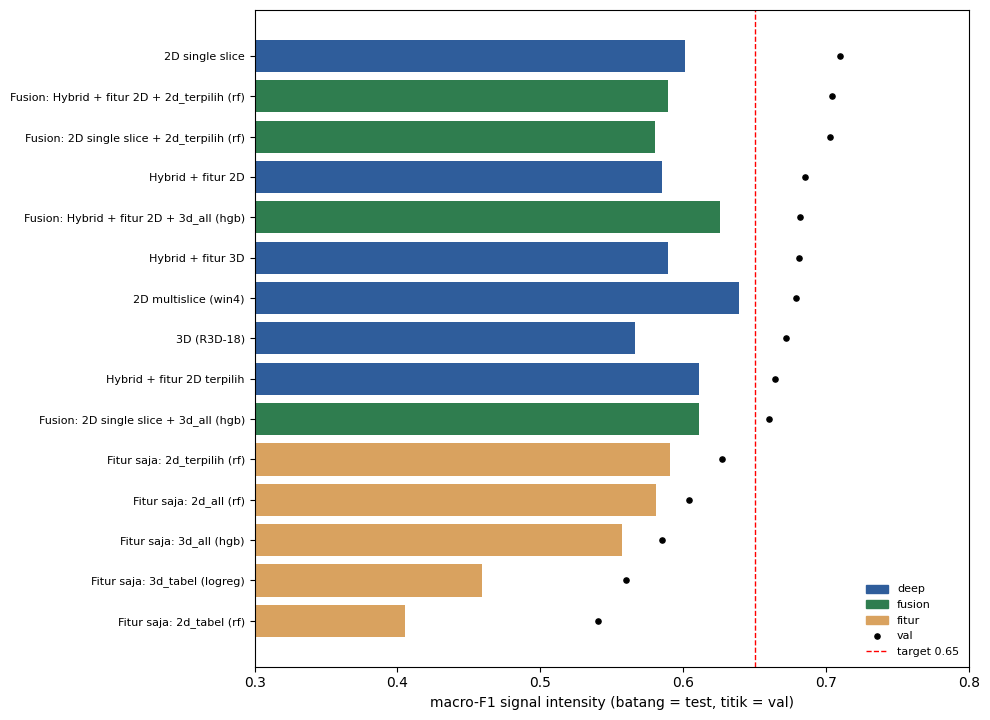

In [20]:
fig, ax = plt.subplots(figsize=(10, 0.42 * len(compare) + 1))
cc = compare.iloc[::-1]
col = {"deep": "#2f5d9b", "fusion": "#2f7d4f", "fitur": "#d9a25f"}
ax.barh(range(len(cc)), cc.ens_test_f1, color=[col[j] for j in cc.jenis])
ax.scatter(cc.ens_val_f1, range(len(cc)), color="k", s=14, zorder=3, label="val")
ax.axvline(TARGET_F1, color="r", ls="--", lw=1, label=f"target {TARGET_F1}")
ax.set_yticks(range(len(cc))); ax.set_yticklabels(cc.eksperimen, fontsize=8); ax.set_xlim(0.3, 0.8)
ax.set_xlabel("macro-F1 signal intensity (batang = test, titik = val)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in col.values()]
ax.legend(handles + ax.get_legend_handles_labels()[0], list(col.keys()) + ["val", f"target {TARGET_F1}"], frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_perbandingan.png"), dpi=150); plt.show()

## 11. Fitur mana yang dipakai model hybrid?

Permutation importance di dalam model hybrid: embedding gambar dihitung sekali, lalu kelompok fitur diacak
dan head dijalankan ulang (val + test, 20 ulangan, rata-rata 3 seed). Ini menjawab apakah fitur benar-benar dipakai
setelah digabung dengan gambar.

Model: Hybrid + fitur 2D
                                         penurunan_f1  sd_seed
SEMUA FITUR                                    0.0897   0.0285
Fraksi piksel > 1,2× normal                    0.0232   0.0065
Skewness                                       0.0149   0.0120
area: inti                                     0.0130   0.0117
area: et                                       0.0115   0.0114
area: ncr                                      0.0115   0.0061
Komposisi (proporsi NCR/edema/ET, luas)        0.0105   0.0104
Kurtosis                                       0.0101   0.0047
Z-score median tumor vs otak normal            0.0093   0.0034
area: tumor_utuh                               0.0088   0.0055
Entropy                                        0.0047   0.0082
Rasio median tumor ÷ median otak normal        0.0026   0.0020
area: sekitar                                  0.0016   0.0045
area: edema                                    0.0014   0.0035
Rasio P10 ÷ otak normal       

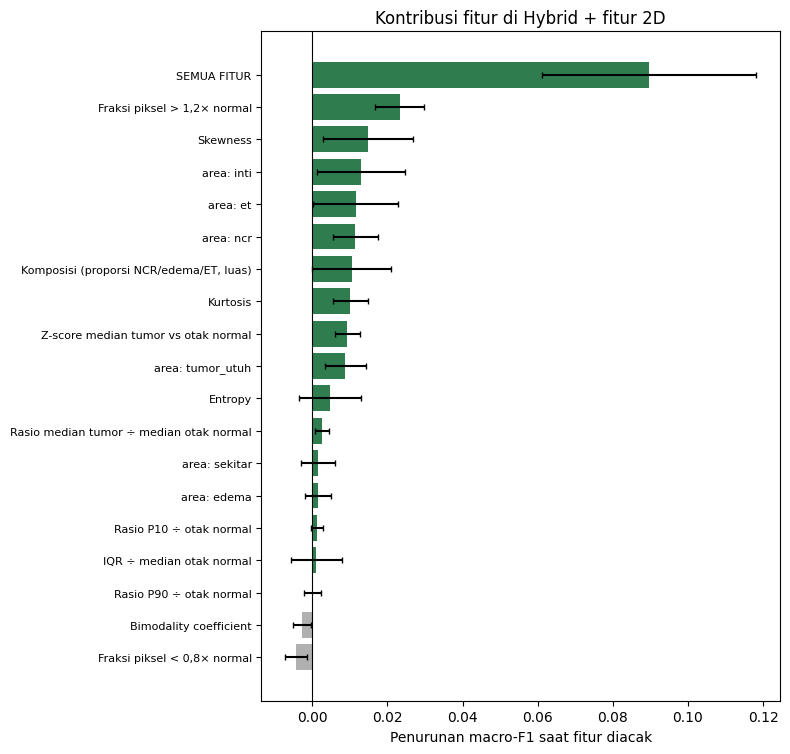

In [21]:
@torch.no_grad()
def hybrid_importance(name, n_rep=20, seed=0):
    exp = EXPS[name]; idx = np.concatenate([split_idx["val"], split_idx["test"]]); y = y_sig[idx]
    fs = FeatStore(exp["fset"], split_idx["train"]); cols = fs.cols
    groups = {}
    for s in STATS:
        g = [cols.index(c) for c in cols if c.endswith("__" + s)]
        if g: groups[STAT_LABEL[s]] = g
    g = [cols.index(c) for c in cols if c.startswith("komposisi__")]
    if g: groups[STAT_LABEL["komposisi"]] = g
    for r in REGIONS:
        g = [cols.index(c) for c in cols if c.startswith(r + "__")]
        if g: groups[f"area: {r}"] = g
    groups["SEMUA FITUR"] = list(range(len(cols)))
    rng = np.random.default_rng(seed); res = {g: [] for g in groups}
    for sd in SEEDS:
        key = run_key(exp, sd)
        m = build_model(exp, fs); m.load_state_dict(torch.load(ckpt_path(key), map_location=DEVICE)); m.eval()
        Z, ML = [], []
        dl = DataLoader(EvalDS(exp, idx, fs), batch_size=128, shuffle=False, num_workers=2)
        for x, f, ii in dl:
            with torch.autocast(**AMP):
                z = m.embed(x.to(DEVICE)); Z.append(z.float()); ML.append(m.mod_head(z).float())
        Z, ML = torch.cat(Z), torch.cat(ML)
        Fx = torch.from_numpy(fs.X[idx]).to(DEVICE)
        head = lambda Fm: m.head(Z, ML, Fm).float().argmax(1).cpu().numpy()
        base = macro_f1(y, head(Fx))
        for gname, gi in groups.items():
            d = []
            for _ in range(n_rep):
                Fp = Fx.clone(); perm = torch.from_numpy(rng.permutation(len(idx))).to(DEVICE)
                Fp[:, gi] = Fx[perm][:, gi]
                d.append(base - macro_f1(y, head(Fp)))
            res[gname].append(np.mean(d))
        del m; torch.cuda.empty_cache()
    out = pd.DataFrame({"penurunan_f1": {g: np.mean(v) for g, v in res.items()}, "sd_seed": {g: np.std(v) for g, v in res.items()}})
    return out.sort_values("penurunan_f1", ascending=False)

HYB_BEST = max([n for n in EXPS if n.startswith("Hybrid")], key=lambda n: deep_res.set_index("eksperimen").loc[n, "ens_val_f1"])
hyb_imp = hybrid_importance(HYB_BEST)
hyb_imp.to_csv(os.path.join(OUT_DIR, "v5_ranking_hybrid.csv"))
print("Model:", HYB_BEST); print(hyb_imp.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 0.35 * len(hyb_imp) + 1))
hh = hyb_imp.iloc[::-1]
ax.barh(range(len(hh)), hh.penurunan_f1, xerr=hh.sd_seed, color=["#2f7d4f" if v > 0 else "#b0b0b0" for v in hh.penurunan_f1], capsize=2)
ax.set_yticks(range(len(hh))); ax.set_yticklabels(hh.index, fontsize=8); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Penurunan macro-F1 saat fitur diacak"); ax.set_title(f"Kontribusi fitur di {HYB_BEST}")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_ranking_hybrid.png"), dpi=150); plt.show()

## 12. Perbandingan runtime: 2D single slice vs 2D multislice vs 3D (dan fitur)

Rata-rata 3 seed di GPU yang sama. Inferensi = 1 pass tanpa TTA per pasien-sequence, termasuk menyiapkan input
(untuk multislice = 9 slice, untuk 3D = 16 slice). Untuk model fitur, waktu ekstraksi fitur ikut dihitung.

In [22]:
rt_rows = []
for name, runs in ALL_RUNS.items():
    exp = EXPS[name]
    feat_ms = FEAT_TIME[FSETS[exp["fset"]][0]] if exp.get("fset") else 0.0
    rt_rows.append(dict(pendekatan=name, slice_per_pasien={"r3d": VOL_DEPTH}.get(exp["arch"], 9 if exp.get("eval") == "win4" else 1),
                        parameter_juta=runs[0]["n_params"] / 1e6, epoch=np.mean([r["epochs"] for r in runs]),
                        detik_per_epoch=np.mean([r["sec_per_epoch"] for r in runs]), training_menit=np.mean([r["minutes"] for r in runs]),
                        gpu_mb_puncak=np.mean([r["peak_mb"] for r in runs]),
                        ekstraksi_fitur_ms=feat_ms, inferensi_ms_per_pasien=np.mean([r["infer_ms"] for r in runs]) + feat_ms,
                        test_f1=deep_res.set_index("eksperimen").loc[name, "test_f1"]))
for dim in ["2d", "3d"]:
    fset, mname = best_feat_model(f"{dim}_all")
    r = fm_res[(fm_res.fitur == fset) & (fm_res.model == mname)].iloc[0]
    rt_rows.append(dict(pendekatan=f"Fitur {dim.upper()} saja ({mname}, CPU)", slice_per_pasien=1 if dim == "2d" else int(n_tumor_slices.median()),
                        parameter_juta=np.nan, epoch=np.nan, detik_per_epoch=np.nan, training_menit=r.fit_s / 60, gpu_mb_puncak=0,
                        ekstraksi_fitur_ms=FEAT_TIME[dim], inferensi_ms_per_pasien=FEAT_TIME[dim] + r.pred_ms, test_f1=r.test_f1))
runtime = pd.DataFrame(rt_rows).round(2)
runtime.to_csv(os.path.join(OUT_DIR, "v5_runtime.csv"), index=False)
runtime

,pendekatan,slice_per_pasien,parameter_juta,epoch,detik_per_epoch,training_menit,gpu_mb_puncak,ekstraksi_fitur_ms,inferensi_ms_per_pasien,test_f1
0,2D single slice,1,21.96,21.33,2.96,1.35,1480.28,0.00,4.91,0.57
1,2D multislice (win4),9,21.96,23.33,3.01,2.24,1479.05,0.00,16.67,0.59
2,3D (R3D-18),16,33.30,28.00,16.56,8.46,1285.10,0.00,9.12,0.58
3,Hybrid + fitur 2D,1,21.98,24.00,3.01,1.54,1478.74,10.81,15.74,0.59
4,Hybrid + fitur 3D,1,21.98,17.67,3.02,1.14,1479.20,124.60,129.43,0.56
5,Hybrid + fitur 2D terpilih,1,21.98,22.67,3.01,1.46,1480.50,10.81,15.79,0.56
6,"Fitur 2D saja (rf, CPU)",1,NaN,NaN,NaN,0.02,0.00,10.81,11.33,0.58
7,"Fitur 3D saja (hgb, CPU)",58,NaN,NaN,NaN,0.02,0.00,124.60,124.68,0.56


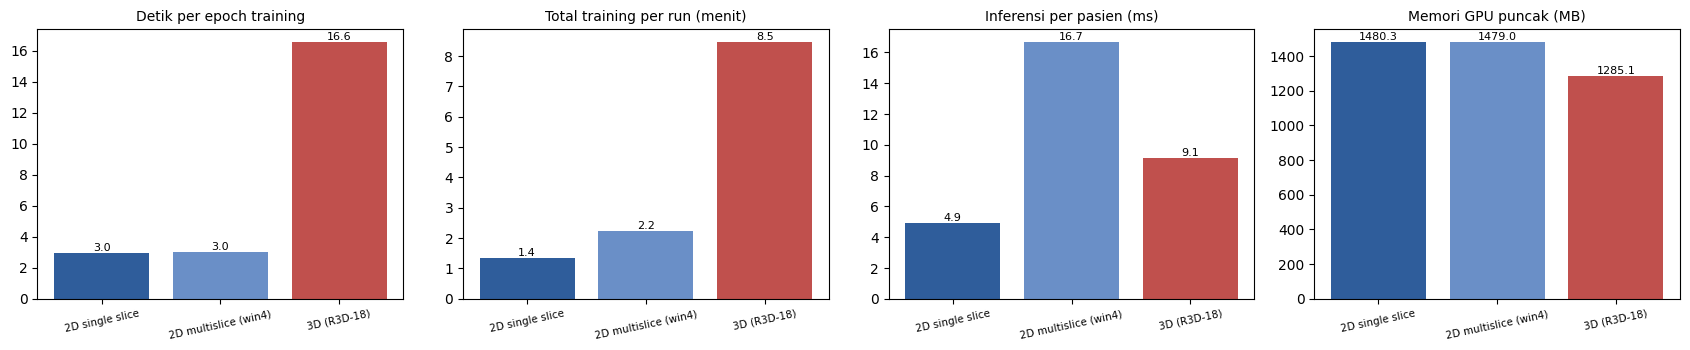

In [23]:
core3 = runtime[runtime.pendekatan.isin(["2D single slice", "2D multislice (win4)", "3D (R3D-18)"])]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, colname, title in [(axes[0], "detik_per_epoch", "Detik per epoch training"), (axes[1], "training_menit", "Total training per run (menit)"),
                           (axes[2], "inferensi_ms_per_pasien", "Inferensi per pasien (ms)"), (axes[3], "gpu_mb_puncak", "Memori GPU puncak (MB)")]:
    ax.bar(core3.pendekatan, core3[colname], color=["#2f5d9b", "#6a8fc7", "#c0504d"])
    for i_, v_ in enumerate(core3[colname]):
        ax.text(i_, v_, f"{v_:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=7.5, rotation=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_runtime.png"), dpi=150); plt.show()

## 12b. Waktu proses 1 pasien baru (end-to-end)

Simulasi penggunaan nyata: **satu pasien masuk → berapa detik sampai keluar prediksi?** Untuk 30 pasien-sequence test
(sama untuk semua pendekatan), setiap tahap diukur terpisah:

1. **Baca data**: membuka file volume pasien dari disk.
2. **Preprocessing**: memilih slice dan membuat input (ROI crop, channel mask; plus versi flip untuk TTA).
3. **Ekstraksi fitur**: hanya untuk model hybrid / fitur.
4. **Model**: forward pass di GPU (1 model, dengan TTA flip seperti saat evaluasi), batch = semua slice milik pasien itu.

Ensemble 3 seed ≈ 3× bagian model. Pemanasan 3 pasien dilakukan dulu dan tidak ikut dihitung.

In [24]:
@torch.no_grad()
def latency_one(name, i, model, fs, feat_model=None):
    exp = EXPS.get(name, {}); r = records.iloc[i]; T = {}
    sync(); t0 = time.perf_counter()
    z = np.load(os.path.join(MS_ROOT, "volumes", r.prefix + ".npz"))
    VOL[r.prefix] = {k: z[k] for k in ["slice_idx", "seg", "t1n", "t2w", "t2f"]}   # isi sama dengan cache
    T["baca_data"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    if model is not None:
        if exp["arch"] == "r3d":
            xs = [input_3d(i, flip=fl) for fl in (False, True)]
        else:
            ks = slice_set(r.prefix, int(r.slice_idx), exp["eval"])
            xs = [input_2d(i, k, flip=fl) for k in ks for fl in (False, True)]
        x = torch.from_numpy(np.stack(xs))
    T["preprocessing"] = time.perf_counter() - t0
    t0 = time.perf_counter(); f = None
    dim = FSETS[exp["fset"]][0] if exp.get("fset") else (feat_model[0] if feat_model else None)
    if dim:
        ks_f = slice_set(r.prefix, int(r.slice_idx), "old") if dim == "2d" else list(range(len(VOL[r.prefix]["slice_idx"])))
        fd, _ = intensity_features(r.prefix, r.modality, ks_f)
    T["ekstraksi_fitur"] = time.perf_counter() - t0
    sync(); t0 = time.perf_counter()
    if model is not None:
        if fs is not None:
            fv = fs.transform(np.array([[fd[c] for c in fs.cols]], np.float32))
            f = torch.from_numpy(np.repeat(fv, len(x), 0)).to(DEVICE)
        with torch.autocast(**AMP):
            ml, sl = model(x.to(DEVICE), f)
        p = sl.float().softmax(1).mean(0).cpu().numpy()
    else:
        cols = FSETS[feat_model[1]][1]
        xf = np.array([[fd[c] for c in cols] + [float(r.modality == m) for m in MOD_CLASSES]], np.float64)
        p = feat_model[2].predict_proba(xf)[0]
    sync(); T["model"] = time.perf_counter() - t0
    return T

LAT_IDX = np.random.default_rng(0).choice(split_idx["test"], size=min(30, len(split_idx["test"])), replace=False)
lat_rows = []
targets = [(n, None) for n in EXPS]
for dim in ["2d", "3d"]:
    fset, mname = best_feat_model(f"{dim}_all")
    fmod = FEAT_MODELS[mname]().fit(fmat(fset)[split_idx["train"]], y_sig[split_idx["train"]])
    targets.append((f"Fitur {dim.upper()} saja ({mname}, CPU)", (dim, fset, fmod)))
for name, fm_ in targets:
    if fm_ is None:
        exp = EXPS[name]; fs = FeatStore(exp["fset"], split_idx["train"]) if exp.get("fset") else None
        model = build_model(exp, fs); model.load_state_dict(torch.load(ckpt_path(run_key(exp, SEEDS[0])), map_location=DEVICE)); model.eval()
    else:
        model, fs = None, None
    for i in LAT_IDX[:3]:
        latency_one(name, int(i), model, fs, fm_)                                      # pemanasan
    for i in LAT_IDX:
        lat_rows.append(dict(pendekatan=name, idx=int(i), **latency_one(name, int(i), model, fs, fm_)))
    del model; torch.cuda.empty_cache()
lat = pd.DataFrame(lat_rows)
STAGES = ["baca_data", "preprocessing", "ekstraksi_fitur", "model"]
lat["total"] = lat[STAGES].sum(1)
lat_sum = lat.groupby("pendekatan", sort=False).agg(**{f"{s}_detik": (s, "mean") for s in STAGES},
                                                     total_detik=("total", "mean"), median_detik=("total", "median"),
                                                     p95_detik=("total", lambda v: np.percentile(v, 95)))
lat_sum["relatif_thd_2D_single"] = lat_sum.total_detik / lat_sum.loc["2D single slice", "total_detik"]
lat_sum = lat_sum.round(4)
lat_sum.to_csv(os.path.join(OUT_DIR, "v5_waktu_per_pasien.csv"))
lat_sum

,baca_data_detik,preprocessing_detik,ekstraksi_fitur_detik,model_detik,total_detik,median_detik,p95_detik,relatif_thd_2D_single
pendekatan,,,,,,,,
2D single slice,0.0455,0.0024,0.0000,0.0091,0.0570,0.0625,0.0873,1.0000
2D multislice (win4),0.0416,0.0217,0.0000,0.0284,0.0918,0.0947,0.1213,1.6095
3D (R3D-18),0.0399,0.0100,0.0000,0.0210,0.0708,0.0716,0.0959,1.2420
Hybrid + fitur 2D,0.0412,0.0022,0.0110,0.0094,0.0638,0.0660,0.0929,1.1178
Hybrid + fitur 3D,0.0426,0.0026,0.1423,0.0101,0.1976,0.2062,0.3185,3.4638
Hybrid + fitur 2D terpilih,0.0419,0.0023,0.0107,0.0093,0.0642,0.0681,0.0904,1.1261
"Fitur 2D saja (rf, CPU)",0.0414,0.0000,0.0109,0.0681,0.1204,0.1221,0.1447,2.1116
"Fitur 3D saja (hgb, CPU)",0.0419,0.0000,0.1398,0.0105,0.1923,0.1961,0.3040,3.3707


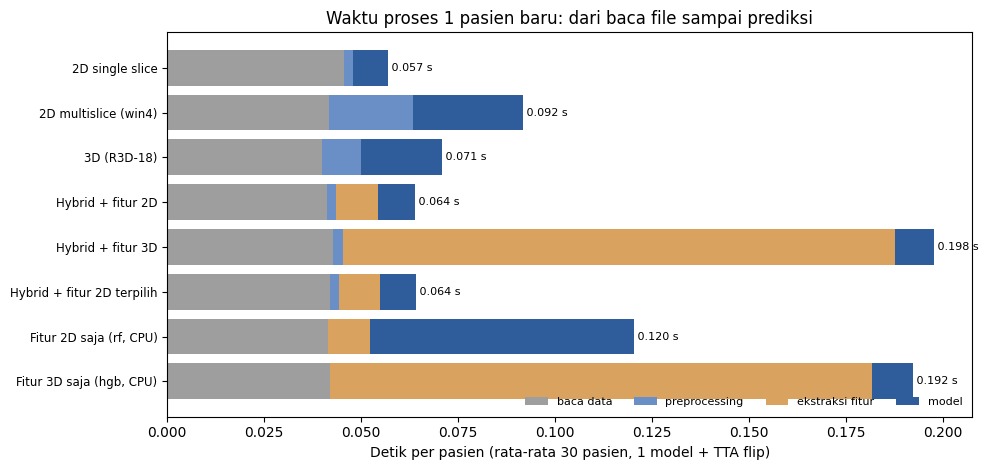

In [25]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(lat_sum) + 1.2))
left = np.zeros(len(lat_sum)); ls_ = lat_sum.iloc[::-1]
for s, c in zip(STAGES, ["#9e9e9e", "#6a8fc7", "#d9a25f", "#2f5d9b"]):
    ax.barh(range(len(ls_)), ls_[f"{s}_detik"], left=left, color=c, label=s.replace("_", " ")); left += ls_[f"{s}_detik"].values
for j, v in enumerate(left):
    ax.text(v, j, f" {v:.3f} s", va="center", fontsize=8)
ax.set_yticks(range(len(ls_))); ax.set_yticklabels(ls_.index, fontsize=8.5)
ax.set_xlabel("Detik per pasien (rata-rata 30 pasien, 1 model + TTA flip)"); ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower right")
ax.set_title("Waktu proses 1 pasien baru: dari baca file sampai prediksi")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_waktu_per_pasien.png"), dpi=150); plt.show()

## 13. Pemilihan model final dengan 5-fold CV per pasien

Val hanya 163 data, jadi urutan di val bisa kebetulan. Tiga kandidat teratas di val (plus baseline 2D single slice)
dievaluasi ulang dengan 5-fold CV per pasien. Model final = CV tertinggi, tetapi kalau selisihnya dengan kandidat yang lebih
sederhana lebih kecil dari 1 sd, dipilih yang lebih sederhana. Test = ensemble 5 model fold.
(Model 3D hanya ikut CV kalau masuk 3 besar, karena training-nya paling lama.)

In [26]:
SIMPLE = {"fitur": 0, "deep": 1, "fusion": 2}
cand = compare[compare.jenis != "fitur"].head(3).eksperimen.tolist()
if "2D single slice" not in cand:
    cand.append("2D single slice")

def fold_feat_probs(fset, mname, k):
    return FEAT_PRED[(fset, mname)]["folds"][k]

cv_rows, CV_PRED = [], {}
for name in cand:
    if name in FUSIONS:
        fu = FUSIONS[name]; deep = fu["deep"]
    else:
        fu, deep = None, name
    runs = [train_run(EXPS[deep], 42, split=FOLDS[k], tag=f"__cv{k}") for k in range(5)]
    f1s, Pts = [], []
    for k, r in enumerate(runs):
        Pv, Pt = np.array(r["eval"]["val"]["p_sig"]), np.array(r["eval"]["test"]["p_sig"])
        if fu:
            fp = fold_feat_probs(fu["fset"], fu["model"], k)
            Pv, Pt = fuse(Pv, fp["val"], fu["w"]), fuse(Pt, fp["test"], fu["w"])
        f1s.append(macro_f1(y_sig[FOLDS[k]["val"]], Pv.argmax(1))); Pts.append(Pt)
    Pt = np.mean(Pts, 0); CV_PRED[name] = Pt
    cv_rows.append(dict(eksperimen=name, jenis="fusion" if fu else "deep", cv_f1=np.mean(f1s), cv_sd=np.std(f1s),
                        per_fold=" / ".join(f"{x:.3f}" for x in f1s),
                        test_f1_ens5=macro_f1(y_sig[split_idx["test"]], Pt.argmax(1)),
                        test_acc_ens5=accuracy_score(y_sig[split_idx["test"]], Pt.argmax(1))))
cv_df = pd.DataFrame(cv_rows).round(3).sort_values("cv_f1", ascending=False)
top = cv_df.iloc[0]
elig = cv_df[cv_df.cv_f1 >= top.cv_f1 - top.cv_sd].copy()
elig["kompleks"] = elig.jenis.map(SIMPLE) + elig.eksperimen.str.contains("3D \\(R3D").astype(int) * 2 + (elig.eksperimen != "2D single slice").astype(int) * 0.5
FINAL = elig.sort_values(["kompleks", "cv_f1"], ascending=[True, False]).iloc[0].eksperimen
cv_df.to_csv(os.path.join(OUT_DIR, "v5_cv5.csv"), index=False)
print("CV tertinggi:", top.eksperimen, f"({top.cv_f1:.3f} ± {top.cv_sd:.3f})")
print("Model final (one-SE, paling sederhana):", FINAL)
cv_df

vit_old__seed=42__cv0: 16 ep, 1.0 min, 3 s/ep, infer 4.8 ms/pasien | val 0.608 test 0.539
vit_old__seed=42__cv1: 21 ep, 1.4 min, 3 s/ep, infer 5.0 ms/pasien | val 0.598 test 0.635
vit_old__seed=42__cv2: 22 ep, 1.4 min, 3 s/ep, infer 5.0 ms/pasien | val 0.644 test 0.545
vit_old__seed=42__cv3: 38 ep, 2.4 min, 3 s/ep, infer 4.9 ms/pasien | val 0.659 test 0.561
vit_old__seed=42__cv4: 18 ep, 1.1 min, 3 s/ep, infer 4.9 ms/pasien | val 0.601 test 0.527
vit_old+2d_all__seed=42__cv0: 20 ep, 1.3 min, 3 s/ep, infer 4.9 ms/pasien | val 0.620 test 0.570
vit_old+2d_all__seed=42__cv1: 15 ep, 1.0 min, 3 s/ep, infer 5.0 ms/pasien | val 0.639 test 0.567
vit_old+2d_all__seed=42__cv2: 33 ep, 2.1 min, 3 s/ep, infer 4.9 ms/pasien | val 0.632 test 0.584
vit_old+2d_all__seed=42__cv3: 23 ep, 1.5 min, 3 s/ep, infer 4.9 ms/pasien | val 0.687 test 0.559
vit_old+2d_all__seed=42__cv4: 20 ep, 1.3 min, 3 s/ep, infer 5.5 ms/pasien | val 0.633 test 0.589
CV tertinggi: Fusion: Hybrid + fitur 2D + 2d_terpilih (rf) (0.653

,eksperimen,jenis,cv_f1,cv_sd,per_fold,test_f1_ens5,test_acc_ens5
1,Fusion: Hybrid + fitur 2D + 2d_terpilih (rf),fusion,0.653,0.018,0.647 / 0.643 / 0.650 / 0.687 / 0.636,0.589,0.620
2,Fusion: 2D single slice + 2d_terpilih (rf),fusion,0.630,0.027,0.609 / 0.626 / 0.658 / 0.663 / 0.593,0.615,0.632
0,2D single slice,deep,0.622,0.025,0.608 / 0.598 / 0.644 / 0.659 / 0.601,0.622,0.637


## 14. Evaluasi detail + top-2 confidence (model final vs baseline)


=== baseline: 2D single slice (ensemble) ===
              precision    recall  f1-score   support

hyperintense      0.740     0.597     0.661        62
 hypointense      0.571     0.500     0.533        24
  isointense      0.652     0.517     0.577        29
       mixed      0.545     0.750     0.632        56

    accuracy                          0.620       171
   macro avg      0.627     0.591     0.601       171
weighted avg      0.638     0.620     0.619       171

Akurasi tipikal / atipikal: 0.730 / 0.500

=== final: Fusion: Hybrid + fitur 2D + 2d_terpilih (rf) (ensemble) ===
              precision    recall  f1-score   support

hyperintense      0.702     0.645     0.672        62
 hypointense      0.522     0.500     0.511        24
  isointense      0.722     0.448     0.553        29
       mixed      0.548     0.714     0.620        56

    accuracy                          0.614       171
   macro avg      0.623     0.577     0.589       171
weighted avg      0.630  

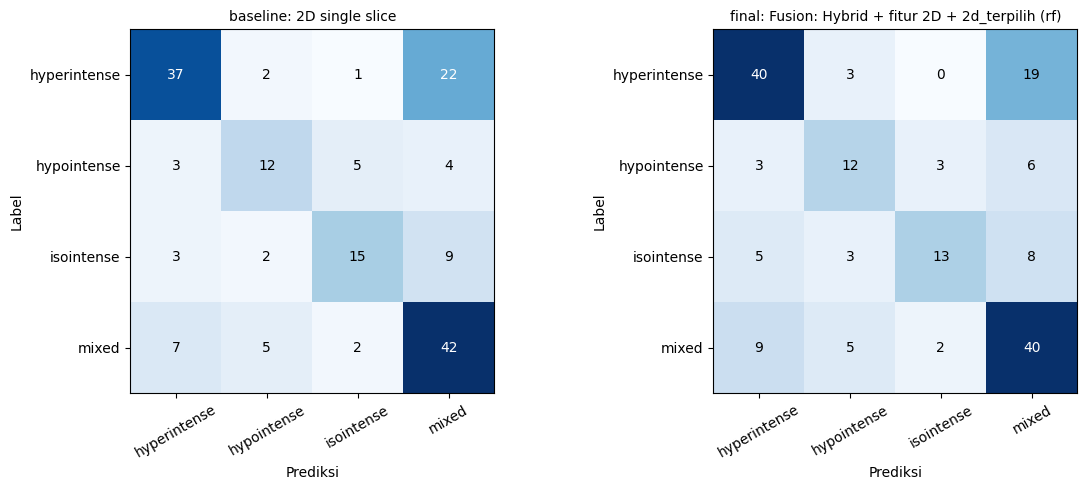

,model,T,ece_before,ece_after,top1_acc,top2_acc,salah,benar_di_posisi2,relevan,sebagian,tidak_relevan
0,baseline: 2D single slice,1.00,0.099,0.099,0.620,0.854,65,0.615,0.354,0.385,0.262
1,final: Fusion: Hybrid + fitur 2D + 2d_terpilih...,0.95,0.093,0.089,0.614,0.895,66,0.727,0.364,0.409,0.227


In [27]:
test_df = records.loc[split_idx["test"]].copy()

def final_probs(name, s):
    if name in FUSIONS:
        fu = FUSIONS[name]
        return fuse(ens(ALL_RUNS[fu["deep"]], s), FEAT_PRED[(fu["fset"], fu["model"])][s], fu["w"])
    return ens(ALL_RUNS[name], s)

HYPER, HYPO, ISO, MIXED = SIG_CLASSES
ORD = {HYPO: 0, ISO: 1, HYPER: 2}
def apply_T(P, T):
    L = np.log(P + 1e-9) / T; L -= L.max(1, keepdims=True); Q = np.exp(L); return Q / Q.sum(1, keepdims=True)
def nll(P, y):
    return -np.log(P[np.arange(len(y)), y] + 1e-9).mean()
def ece(P, y, bins=10):
    conf, pred = P.max(1), P.argmax(1); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e
def mentioned(sentence):
    s_ = str(sentence).lower(); m = set()
    if re.search(r"\bhyper\w*|\bhigh\b|\bbright\w*", s_): m.add(HYPER)
    if re.search(r"\bhypo\w*|\blow\b|\bdark\w*", s_): m.add(HYPO)
    if re.search(r"\biso\w*", s_): m.add(ISO)
    if re.search(r"\bmix\w*|\bheterogen\w*", s_): m.add(MIXED)
    return m
def relevance(a, b, sentence, true):
    R = mentioned(sentence) | {true}
    if len(R & {HYPER, HYPO, ISO}) >= 2: R.add(MIXED)
    if a in R and b in R: return "relevan"
    if a in ORD and b in ORD and abs(ORD[a] - ORD[b]) == 1: return "relevan"
    if MIXED in (a, b) and (b if a == MIXED else a) in R: return "sebagian"
    return "tidak relevan"

typical = records[records.split == "train"].groupby(["modality", "category"]).signal_label.agg(lambda s: s.value_counts().idxmax())
test_df["typical"] = [typical.get((m, c)) == l for m, c, l in zip(test_df.modality, test_df.category, test_df.signal_label)]
show = {"baseline: 2D single slice": "2D single slice", f"final: {FINAL}": FINAL}
top2_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
yv, yt = y_sig[split_idx["val"]], y_sig[split_idx["test"]]
for ax, (lab, name) in zip(axes, show.items()):
    Pv, Pt = final_probs(name, "val"), final_probs(name, "test")
    pred = [SIG_CLASSES[i] for i in Pt.argmax(1)]
    print(f"\n=== {lab} (ensemble) ===")
    print(classification_report(test_df.signal_label, pred, labels=SIG_CLASSES, digits=3, zero_division=0))
    t = test_df.assign(pred=pred)
    print("Akurasi tipikal / atipikal:", f"{(t[t.typical].pred == t[t.typical].signal_label).mean():.3f} / "
          f"{(t[~t.typical].pred == t[~t.typical].signal_label).mean():.3f}")
    cm = confusion_matrix(test_df.signal_label, pred, labels=SIG_CLASSES)
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(SIG_CLASSES, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(SIG_CLASSES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label"); ax.set_title(lab, fontsize=10)
    Ts = np.linspace(0.3, 3.0, 55); T = float(Ts[np.argmin([nll(apply_T(Pv, t_), yv) for t_ in Ts])])
    Pc = apply_T(Pt, T); o = np.argsort(-Pc, 1)
    d = test_df.assign(top1=[SIG_CLASSES[i] for i in o[:, 0]], top2=[SIG_CLASSES[i] for i in o[:, 1]])
    d["rel"] = [relevance(a, b, s_, l) for a, b, s_, l in zip(d.top1, d.top2, d.source_sentence, d.signal_label)]
    w = d[d.top1 != d.signal_label]
    top2_rows.append(dict(model=lab, T=T, ece_before=ece(Pt, yt), ece_after=ece(Pc, yt), top1_acc=(d.top1 == d.signal_label).mean(),
                          top2_acc=((d.top1 == d.signal_label) | (d.top2 == d.signal_label)).mean(), salah=len(w),
                          benar_di_posisi2=(w.top2 == w.signal_label).mean(), relevan=(w.rel == "relevan").mean(),
                          sebagian=(w.rel == "sebagian").mean(), tidak_relevan=(w.rel == "tidak relevan").mean()))
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "v5_confusion.png"), dpi=150); plt.show()
top2_df = pd.DataFrame(top2_rows).round(3)
top2_df.to_csv(os.path.join(OUT_DIR, "v5_top2.csv"), index=False)
top2_df

## 15. Ringkasan

In [28]:
summary = dict(
    target_f1=TARGET_F1, final=FINAL,
    perbandingan=json.loads(compare.to_json(orient="records")),
    cv5=json.loads(cv_df.to_json(orient="records")),
    runtime=json.loads(runtime.to_json(orient="records")),
    ranking_statistik=json.loads(rank_stat.reset_index().to_json(orient="records")),
    ranking_area=json.loads(rank_reg.reset_index().to_json(orient="records")),
    ranking_hybrid=dict(model=HYB_BEST, hasil=json.loads(hyb_imp.reset_index().to_json(orient="records"))),
    fitur_terpilih=dict(dim=RANK_DIM, statistik=keep_stat, area=keep_reg, n=len(SEL_COLS)),
    fusion=FUSIONS, top2=json.loads(top2_df.to_json(orient="records")),
    waktu_ekstraksi_fitur_ms=FEAT_TIME,
    waktu_per_pasien_detik=json.loads(lat_sum.reset_index().to_json(orient="records")),
)
json.dump(summary, open(os.path.join(OUT_DIR, "v5_summary.json"), "w"), indent=2, default=float)
print("Model final:", FINAL)
print(compare[["eksperimen", "ens_val_f1", "ens_test_f1", "capai_0.65"]].to_string(index=False))
print(cv_df[["eksperimen", "cv_f1", "cv_sd", "test_f1_ens5"]].to_string(index=False))

Model final: Fusion: Hybrid + fitur 2D + 2d_terpilih (rf)
                                  eksperimen  ens_val_f1  ens_test_f1 capai_0.65
                             2D single slice       0.710        0.601      belum
Fusion: Hybrid + fitur 2D + 2d_terpilih (rf)       0.704        0.589      belum
  Fusion: 2D single slice + 2d_terpilih (rf)       0.703        0.580      belum
                           Hybrid + fitur 2D       0.685        0.585      belum
    Fusion: Hybrid + fitur 2D + 3d_all (hgb)       0.682        0.626      belum
                           Hybrid + fitur 3D       0.681        0.589      belum
                        2D multislice (win4)       0.679        0.639      belum
                                 3D (R3D-18)       0.672        0.566      belum
                  Hybrid + fitur 2D terpilih       0.664        0.611      belum
      Fusion: 2D single slice + 3d_all (hgb)       0.660        0.611      belum
                Fitur saja: 2d_terpilih (rf)       